# Module 2 — Neural Networks

Classificazione del **Severity Impairment Index (`sii`)** sul dataset CMI con reti neurali.

Il preprocessing (split, scaling, encoding) è **identico** a quello del notebook di Logistic Regression,
così i risultati dei diversi classificatori del Modulo 2 sono confrontabili sullo stesso test set.

**Struttura**
1. Setup
2. Caricamento dati e preprocessing (comune al Modulo 2)
3. Funzioni di valutazione
4. Baseline: Dummy, Perceptron, MLP di default
5. MLP (scikit-learn): hyper-parameter tuning
6. Rete in Keras: overfitting e regolarizzazione (Early Stopping, L2, Dropout, class weight,
   Batch Normalization, L1, SGD con momentum, learning rate decrescente)
7. Rete in Keras: confronto fra architetture (piccola, media, grande)
8. Rete in Keras: hyper-parameter tuning
9. Confronto finale
10. Sintesi per il report

> **Legenda.** I blocchi **📌 Report** indicano cosa riportare nel report (tabelle, grafici, frasi chiave).
> I numeri citati nei commenti vengono dal run di riferimento: rieseguendo possono cambiare leggermente
> (soprattutto per Keras); in quel caso vanno aggiornati.

**Tempo di esecuzione** del notebook completo: circa 14-15 minuti su CPU (circa 3 minuti per l'MLP di default e
circa 7,5 minuti per le due ricerche di iperparametri, sezioni 5 e 8).

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'   # nasconde i log interni di TensorFlow

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay,
                             roc_curve, auc, roc_auc_score,
                             precision_recall_curve, average_precision_score)

import tensorflow as tf
from tensorflow import keras
from keras import layers, regularizers
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from scikeras.wrappers import KerasClassifier

RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)   # fissa i seed di Python, NumPy e TensorFlow
plt.rcParams['figure.figsize'] = (7, 5)

## 2. Caricamento dati e preprocessing

Stesso codice del notebook di Logistic Regression: split stratificato 80/20 con `random_state=42`,
`StandardScaler` sulle numeriche e `OneHotEncoder(drop='first')` sulle colonne `Season`, tutto dentro
un `ColumnTransformer` fittato solo sul train (anche dentro ogni fold della cross-validation).

Per le reti neurali lo scaling è particolarmente importante: con feature su scale molto diverse
(es. `BIA-BIA_DEE` in migliaia, `PAQ_C_Total` fra 1 e 5) la discesa del gradiente converge male.

In [2]:
df = pd.read_csv('cmi_internet_final.csv')
print('Shape:', df.shape, '| valori mancanti:', df.isna().sum().sum())

y = df['sii']
X = df.drop(columns=['id', 'sii'])

cat_cols = [c for c in X.columns if 'Season' in c]
num_cols = [c for c in X.columns if c not in cat_cols]
print(f'{len(num_cols)} feature numeriche, {len(cat_cols)} categoriche')

dist = y.value_counts().sort_index()
print(pd.DataFrame({'n': dist, '%': (dist / len(y) * 100).round(2)}))

Shape: (8460, 50) | valori mancanti: 0
38 feature numeriche, 10 categoriche
        n      %
sii             
0    5833  68.95
1    1587  18.76
2     952  11.25
3      88   1.04


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Classi nel test:', y_test.value_counts().sort_index().to_dict())

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
])

CLASSI = [0, 1, 2, 3]

Train: (6768, 48) | Test: (1692, 48)
Classi nel test: {0: 1167, 1: 317, 2: 190, 3: 18}


📌 **Report:** non serve ripetere il preprocessing (è descritto una volta sola per tutto il Modulo 2).
Basta ricordare che la classe 3 ha solo **18 esempi nel test set**: le sue metriche sono molto instabili.

## 3. Funzioni di valutazione

Su un target così sbilanciato (classe 3 ≈ 1%) l'accuracy è fuorviante: il classificatore banale ottiene già il 69%.
La metrica usata per il tuning e per scegliere i modelli è la **F1-macro**; accanto si riportano accuracy,
balanced accuracy, ROC AUC macro (one-vs-rest) e la F1 di ogni classe, come negli altri notebook del Modulo 2.

In [4]:
risultati = []

def valuta_prob(nome, y_pred, y_prob=None, stampa=True):
    f1_classi = f1_score(y_test, y_pred, average=None, labels=CLASSI, zero_division=0)
    res = {
        'modello': nome,
        'accuracy': accuracy_score(y_test, y_pred),
        'balanced_acc': balanced_accuracy_score(y_test, y_pred),
        'f1_macro': f1_score(y_test, y_pred, average='macro'),
        'roc_auc': (roc_auc_score(y_test, y_prob, multi_class='ovr', average='macro')
                    if y_prob is not None else np.nan),
    }
    for k, v in zip(CLASSI, f1_classi):
        res[f'f1_{k}'] = v
    if stampa:
        print(f'=== {nome} ===')
        print({k: round(float(v), 3) for k, v in res.items() if k != 'modello'})
        print(classification_report(y_test, y_pred, digits=3, zero_division=0))
    return res


def valuta(nome, modello, stampa=True):
    """Per modelli sklearn/scikeras gia' fittati (pipeline comprese)."""
    y_pred = modello.predict(X_test)
    y_prob = modello.predict_proba(X_test) if hasattr(modello, 'predict_proba') else None
    return valuta_prob(nome, y_pred, y_prob, stampa=stampa)


def plot_confusion(y_pred, titolo, y_true=None):
    y_true = y_test if y_true is None else y_true
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=CLASSI, colorbar=False)
    plt.title(titolo); plt.tight_layout(); plt.show()


def plot_roc_pr(y_prob, titolo):
    """Curve ROC e Precision-Recall one-vs-rest, una per classe."""
    y_bin = label_binarize(y_test, classes=CLASSI)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for k in CLASSI:
        fpr, tpr, _ = roc_curve(y_bin[:, k], y_prob[:, k])
        axes[0].plot(fpr, tpr, label=f'classe {k} (AUC = {auc(fpr, tpr):.2f})')
        prec, rec, _ = precision_recall_curve(y_bin[:, k], y_prob[:, k])
        ap = average_precision_score(y_bin[:, k], y_prob[:, k])
        axes[1].plot(rec, prec, label=f'classe {k} (AP = {ap:.2f}, base = {y_bin[:, k].mean():.2f})')
    axes[0].plot([0, 1], [0, 1], 'k--', lw=.8)
    axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title('ROC one-vs-rest'); axes[0].legend(fontsize=8)
    axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
    axes[1].set_title('Precision-Recall one-vs-rest'); axes[1].legend(fontsize=8)
    plt.suptitle(titolo); plt.tight_layout(); plt.show()


def plot_history(history, titolo):
    """Curve di loss e accuracy su train e validation (Keras)."""
    h = history.history if hasattr(history, 'history') else history
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h['loss'], label='train'); axes[0].plot(h['val_loss'], label='validation')
    axes[0].set_xlabel('epoca'); axes[0].set_ylabel('loss'); axes[0].set_title('Loss'); axes[0].legend()
    axes[1].plot(h['accuracy'], label='train'); axes[1].plot(h['val_accuracy'], label='validation')
    axes[1].set_xlabel('epoca'); axes[1].set_ylabel('accuracy'); axes[1].set_title('Accuracy'); axes[1].legend()
    plt.suptitle(titolo); plt.tight_layout(); plt.show()

## 4. Baseline

- **Dummy**: predice sempre la classe più frequente. È la soglia minima da battere.
- **Perceptron**: un singolo strato lineare, senza hidden layer. Mostra cosa si ottiene con una frontiera
  di decisione lineare (vedi l'esempio dello XOR a lezione).
- **MLP di default**: `MLPClassifier` con i parametri di default (1 hidden layer da 100 neuroni, ReLU, Adam).

=== Perceptron ===
{'accuracy': 0.571, 'balanced_acc': 0.298, 'f1_macro': 0.294, 'roc_auc': nan, 'f1_0': 0.734, 'f1_1': 0.195, 'f1_2': 0.206, 'f1_3': 0.043}
              precision    recall  f1-score   support

           0      0.725     0.744     0.734      1167
           1      0.222     0.174     0.195       317
           2      0.193     0.221     0.206       190
           3      0.034     0.056     0.043        18

    accuracy                          0.571      1692
   macro avg      0.294     0.298     0.294      1692
weighted avg      0.564     0.571     0.567      1692



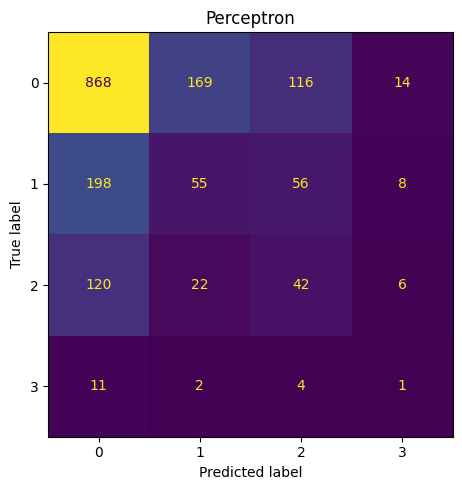

In [5]:
dummy = Pipeline([('prep', clone(preprocessor)),
                  ('clf', DummyClassifier(strategy='most_frequent'))]).fit(X_train, y_train)
risultati.append(valuta('Dummy (most frequent)', dummy, stampa=False))

perc = Pipeline([('prep', clone(preprocessor)),
                 ('clf', Perceptron(random_state=RANDOM_STATE))]).fit(X_train, y_train)
risultati.append(valuta('Perceptron', perc))   # nessuna predict_proba -> ROC AUC non calcolata
plot_confusion(perc.predict(X_test), 'Perceptron')

Addestramento: 171.2s, 300 iterazioni
=== MLP default ===
{'accuracy': 0.583, 'balanced_acc': 0.293, 'f1_macro': 0.293, 'roc_auc': 0.598, 'f1_0': 0.74, 'f1_1': 0.226, 'f1_2': 0.207, 'f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.727     0.754     0.740      1167
           1      0.235     0.218     0.226       317
           2      0.215     0.200     0.207       190
           3      0.000     0.000     0.000        18

    accuracy                          0.583      1692
   macro avg      0.294     0.293     0.293      1692
weighted avg      0.570     0.583     0.576      1692



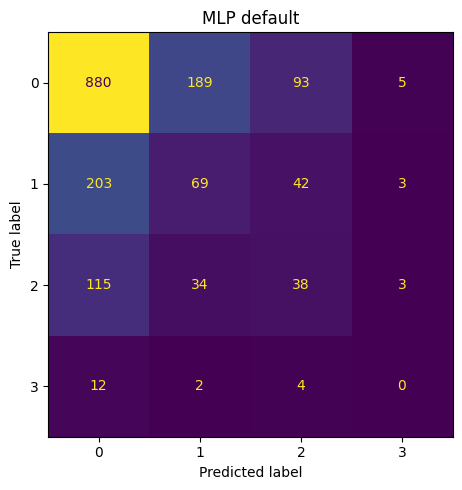

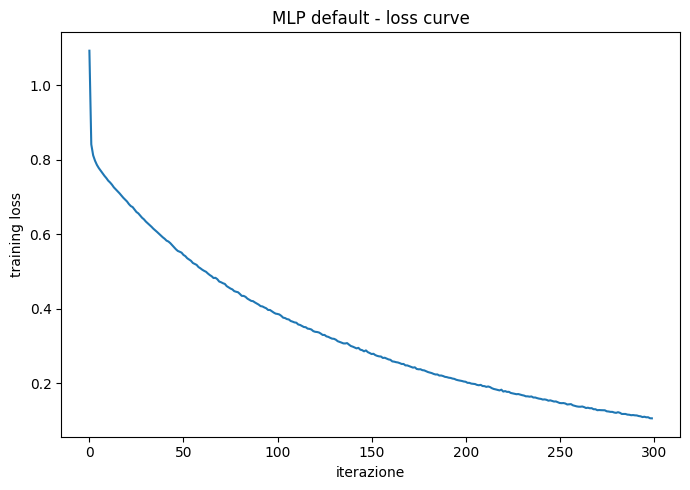

In [6]:
t0 = time.time()
mlp_base = Pipeline([('prep', clone(preprocessor)),
                     ('clf', MLPClassifier(random_state=RANDOM_STATE, max_iter=300))])
mlp_base.fit(X_train, y_train)
print(f'Addestramento: {time.time() - t0:.1f}s, {mlp_base.named_steps["clf"].n_iter_} iterazioni')
risultati.append(valuta('MLP default', mlp_base))
plot_confusion(mlp_base.predict(X_test), 'MLP default')

plt.plot(mlp_base.named_steps['clf'].loss_curve_)
plt.xlabel('iterazione'); plt.ylabel('training loss'); plt.title('MLP default - loss curve')
plt.tight_layout(); plt.show()

**Commento.** Il Dummy ha accuracy 0.690 ma F1-macro 0.204, perché non predice mai le classi 1, 2 e 3: è il motivo per cui la scelta dei modelli si fa sulla F1-macro. Perceptron (0.294) e MLP di default (0.293) hanno praticamente la stessa F1-macro (dalle confusion matrix: il Perceptron distribuisce un po' di più le predizioni sulle classi minoritarie e individua 1 dei 18 casi della classe 3, che l'MLP non predice mai): **aggiungere un hidden layer, senza tuning, non porta guadagni**. Il segnale nei dati è debole e in gran parte già catturabile da una frontiera lineare (lo stesso indica la Logistic Regression).

La loss di training dell'MLP di default scende per tutte le 300 iterazioni senza stabilizzarsi: la rete continua ad adattarsi sempre di più al training set. Da sola questa curva **non basta per parlare di overfitting**, perché manca la curva di validazione: l'overfitting viene verificato nella sezione 6, dove si confrontano loss di training e di validazione.

📌 **Report:** riga Dummy e riga Perceptron nella tabella finale come riferimento minimo; una frase sul fatto che Perceptron ≈ MLP di default.

## 5. MLP (scikit-learn): hyper-parameter tuning

Ricerca randomizzata con 5-fold stratificata, ottimizzando la **F1-macro**.

| Parametro | Valori | Motivazione |
|---|---|---|
| `hidden_layer_sizes` | 1–2 strati, 32–128 neuroni | capacità del modello (profondità e larghezza) |
| `activation` | relu, tanh | le due attivazioni più usate per gli hidden layer (vedi slide) |
| `alpha` | 1e-4 → 1 | regolarizzazione L2 sui pesi |
| `learning_rate_init` | 1e-3, 1e-2 | passo della discesa del gradiente |
| `batch_size` | 64, 128 | dimensione dei mini-batch |
| `early_stopping` | True/False | interrompe il training quando lo score di validazione (accuracy) smette di migliorare |

**Scelte per contenere i tempi** (da citare nel report come motivazione della griglia):
- `max_iter=200`: nelle prove le reti migliori convergono (o si stabilizzano) entro 100-200 epoche;
- esclusi `learning_rate_init=1e-4` e `batch_size=32`, che rallentano molto la convergenza senza
  migliorare la F1-macro in prove preliminari;
- `logistic` escluso perché con più strati soffre di vanishing gradient (saturazione della sigmoide).

In [7]:
N_ITER_MLP = 15   # configurazioni provate (15 x 5 fold = 75 addestramenti)

param_mlp = {
    'clf__hidden_layer_sizes': [(32,), (64,), (128,), (64, 32), (128, 64)],
    'clf__activation': ['relu', 'tanh'],
    'clf__alpha': [1e-4, 1e-3, 1e-2, 1e-1, 1],
    'clf__learning_rate_init': [1e-3, 1e-2],
    'clf__batch_size': [64, 128],
    'clf__early_stopping': [True, False],
}

rs_mlp = RandomizedSearchCV(
    Pipeline([('prep', clone(preprocessor)),
              ('clf', MLPClassifier(max_iter=200, random_state=RANDOM_STATE))]),
    param_mlp, n_iter=N_ITER_MLP, scoring='f1_macro',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1)

t0 = time.time()
rs_mlp.fit(X_train, y_train)
print(f'Ricerca completata in {time.time() - t0:.0f}s')
print('Migliori parametri:', rs_mlp.best_params_)
print('F1-macro in CV:', round(rs_mlp.best_score_, 4))

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Ricerca completata in 153s
Migliori parametri: {'clf__learning_rate_init': 0.001, 'clf__hidden_layer_sizes': (32,), 'clf__early_stopping': False, 'clf__batch_size': 64, 'clf__alpha': 0.0001, 'clf__activation': 'tanh'}
F1-macro in CV: 0.2994


In [8]:
# Tabella delle configurazioni provate (da riportare nel report)
cols = ['param_' + p for p in param_mlp] + ['mean_test_score', 'std_test_score', 'rank_test_score']
tab_mlp = (pd.DataFrame(rs_mlp.cv_results_)[cols]
           .rename(columns=lambda c: c.replace('param_clf__', ''))
           .sort_values('rank_test_score'))
tab_mlp.round(4)

,hidden_layer_sizes,activation,alpha,learning_rate_init,batch_size,early_stopping,mean_test_score,std_test_score,rank_test_score
3,"(32,)",tanh,0.0001,0.001,64,False,0.2994,0.0106,1
7,"(128,)",relu,0.0100,0.001,64,False,0.2969,0.0080,2
12,"(64, 32)",relu,0.0010,0.001,64,False,0.2945,0.0125,3
13,"(64,)",relu,0.0010,0.001,128,False,0.2939,0.0150,4
14,"(64,)",relu,0.1000,0.001,64,False,0.2934,0.0082,5
2,"(64,)",relu,0.0001,0.010,128,False,0.2895,0.0077,6
4,"(64,)",relu,0.0100,0.010,64,False,0.2854,0.0184,7
5,"(128,)",relu,0.0100,0.001,64,True,0.2602,0.0197,8
1,"(32,)",tanh,0.0100,0.001,64,True,0.2597,0.0142,9
8,"(64, 32)",tanh,0.0010,0.001,128,True,0.2533,0.0168,10


In [9]:
# Effetto di early_stopping: F1-macro media in CV delle configurazioni con e senza
tab_mlp.groupby('early_stopping')['mean_test_score'].agg(['mean', 'max', 'count']).round(4)

,mean,max,count
early_stopping,,,
False,0.2933,0.2994,7
True,0.2447,0.2602,8


=== MLP tuned ===
{'accuracy': 0.598, 'balanced_acc': 0.294, 'f1_macro': 0.294, 'roc_auc': 0.589, 'f1_0': 0.756, 'f1_1': 0.23, 'f1_2': 0.189, 'f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.735     0.779     0.756      1167
           1      0.257     0.208     0.230       317
           2      0.188     0.189     0.189       190
           3      0.000     0.000     0.000        18

    accuracy                          0.598      1692
   macro avg      0.295     0.294     0.294      1692
weighted avg      0.576     0.598     0.586      1692



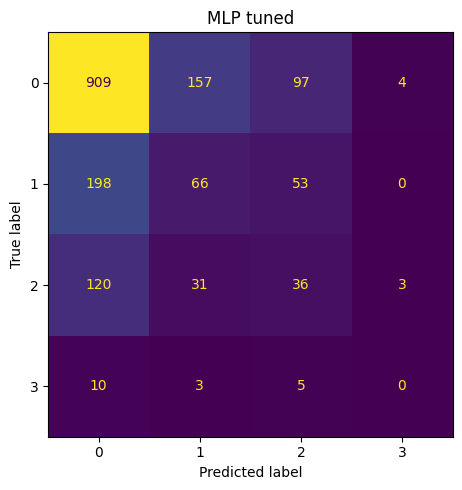

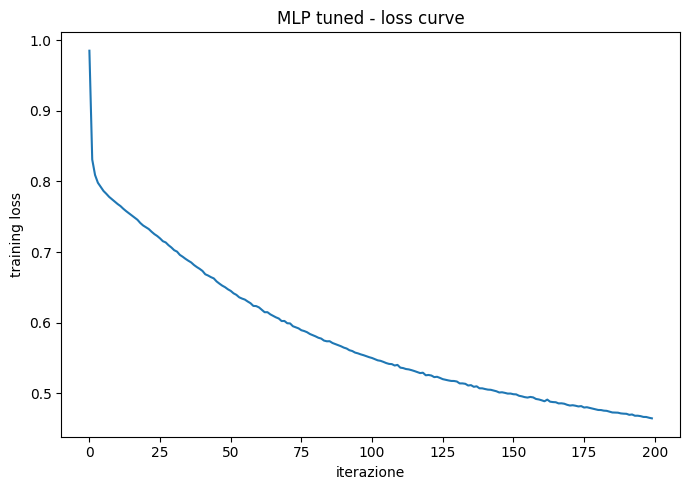

In [10]:
mlp_best = rs_mlp.best_estimator_
risultati.append(valuta('MLP tuned', mlp_best))
plot_confusion(mlp_best.predict(X_test), 'MLP tuned')

plt.plot(mlp_best.named_steps['clf'].loss_curve_)
plt.xlabel('iterazione'); plt.ylabel('training loss'); plt.title('MLP tuned - loss curve')
plt.tight_layout(); plt.show()

**Commento.**
- Miglior configurazione: **1 hidden layer da 32 neuroni, tanh, alpha=1e-4, learning rate 1e-3, batch 64, senza early stopping**, F1-macro in CV **0.299**. Sul test la F1-macro è 0.294, in linea con la CV: il tuning non ha prodotto overfitting sulla validazione.
- **Il risultato più interessante è l'effetto di `early_stopping`**: tutte le 7 configurazioni senza early stopping occupano le prime 7 posizioni (F1-macro media 0.293), tutte quelle con early stopping le ultime 8 (media 0.245). In sklearn l'early stopping monitora l'**accuracy** sulla validazione, e su un dataset sbilanciato l'accuracy è massima già quando la rete predice quasi sempre la classe 0: il training si ferma prima che la rete impari le classi minoritarie. La stessa cosa si vede in Keras (sezione 6.2). Il confronto è un'**indicazione**, non una misura controllata (7 contro 8 configurazioni, con altri iperparametri diversi), ma la separazione è netta: la peggiore configurazione senza early stopping (0.285) supera la migliore con early stopping (0.260).
- Le prime 7 configurazioni stanno tutte fra 0.285 e 0.299, con deviazioni standard fra i fold di 0.01-0.02: **le differenze fra architetture sono dello stesso ordine della variabilità fra i fold**. Profondità, larghezza e alpha contano poco; reti piccole (32-64 neuroni, un solo strato) bastano.
- La loss del modello finale scende ancora alla 200ª iterazione (limite `max_iter`): la rete non ha raggiunto la convergenza, ma lasciarla andare avanti farebbe solo aumentare l'adattamento al training set (vedi MLP di default, 300 iterazioni, stessa F1).
- L'MLP di sklearn non supporta `class_weight`, quindi non ha modo di dare più peso alle classi rare: la classe 3 non viene mai predetta (F1 = 0).

📌 **Report:** tabella `tab_mlp` (anche solo le prime 5 righe + le ultime 2), la tabella del confronto `early_stopping` True/False, e la spiegazione del perché l'early stopping basato sull'accuracy peggiora la F1-macro.

## 6. Rete in Keras: overfitting e regolarizzazione

Con Keras si ha il controllo diretto sull'andamento del training epoca per epoca, e quindi si può studiare
l'**overfitting** e i **criteri di convergenza** che lo evitano, come chiesto dalle guidelines.

Dal training set si ritaglia un **validation set** stratificato (15%), usato per:
- monitorare la loss durante il training (curve, early stopping);
- **confrontare le varianti fra loro**: in questa sezione e nella 7 i confronti e le scelte si basano solo sul
  validation set, così il test set resta riservato alla valutazione finale (sezione 9).

Quando si usano i pesi di classe, la loss di validazione viene **pesata con gli stessi pesi** del training
(in Keras `class_weight` agisce solo sul training): così early stopping e curve di validazione misurano lo stesso
obiettivo che la rete ottimizza.

Il preprocessor viene fittato solo sulla parte di training. Il validation set è piccolo (1016 righe, 11 esempi
della classe 3): le differenze fra varianti di pochi millesimi non sono significative. Inoltre è lo stesso set usato
dall'early stopping per scegliere l'epoca migliore, quindi le metriche di validazione sono **leggermente
ottimistiche**, in modo simile per tutte le varianti tranne "no reg" (che non usa l'early stopping).

Esperimenti, tutti con la stessa architettura di partenza (128-64, ReLU, Adam):
1. **nessuna regolarizzazione**, 150 epoche → ci si aspetta overfitting;
2. **Early Stopping** sulla `val_loss`;
3. **L2** sui pesi;
4. **Dropout**;
5. **Dropout + class weight**: i pesi delle classi nella loss, come `class_weight='balanced'` usato in
   Logistic Regression e SVM (è un parametro dell'algoritmo, non una tecnica di resampling).

Partendo dalla variante 5, si provano poi altre tecniche, una alla volta:

6. **Batch Normalization** dopo ogni hidden layer;
7. **regolarizzazione L1** aggiunta alla variante 5 (che non ha L2: solo dropout e class weight);
8. **SGD con momentum** al posto di Adam;
9. **learning rate decrescente** (`ReduceLROnPlateau`).

In [11]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE)

prep_keras = clone(preprocessor).fit(X_tr)   # fittato solo sulla parte di training
X_tr_p  = prep_keras.transform(X_tr).astype('float32')
X_val_p = prep_keras.transform(X_val).astype('float32')
X_te_p  = prep_keras.transform(X_test).astype('float32')

n_features = X_tr_p.shape[1]
n_classes = len(CLASSI)
print('Train:', X_tr_p.shape, '| Validation:', X_val_p.shape, '| Test:', X_te_p.shape)

Train: (5752, 68) | Validation: (1016, 68) | Test: (1692, 68)


In [12]:
HIDDEN = (128, 64)
EPOCHS = 150      # massimo; con early stopping il training si ferma prima
BATCH_SIZE = 128
LR = 1e-3

def make_net(n_in, n_out, hidden=HIDDEN, activation='relu', reg_type='l2', reg=0.0,
             dropout=0.0, batchnorm=False, optimizer='adam', lr=LR, momentum=0.0):
    """Rete feed-forward. Ogni hidden layer: Dense -> [BatchNorm] -> attivazione -> [Dropout]."""
    model = keras.Sequential([keras.Input(shape=(n_in,))])
    for units in hidden:
        if reg > 0:
            kr = regularizers.l1(reg) if reg_type == 'l1' else regularizers.l2(reg)
        else:
            kr = None
        model.add(layers.Dense(units, kernel_regularizer=kr))
        if batchnorm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation(activation))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(n_out, activation='softmax'))
    if optimizer == 'adam':
        opt = keras.optimizers.Adam(learning_rate=lr)
    else:
        opt = keras.optimizers.SGD(learning_rate=lr, momentum=momentum)
    model.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def build_model(**kwargs):
    return make_net(n_features, n_classes, **kwargs)


risultati_val = []   # metriche sul validation set: servono a confrontare le varianti (sezioni 6 e 7)

def train_and_eval(nome, model, callbacks=None, class_weight=None, epochs=EPOCHS):
    # In Keras class_weight pesa solo la loss di training. Per far misurare alla val_loss lo stesso
    # obiettivo (early stopping e ReduceLROnPlateau la usano), alla validazione si passano gli stessi
    # pesi come sample_weight.
    if class_weight is not None:
        w_val = y_val.map(class_weight).values.astype('float32')
        val_data = (X_val_p, y_val, w_val)
    else:
        val_data = (X_val_p, y_val)

    t0 = time.time()
    hist = model.fit(X_tr_p, y_tr, validation_data=val_data,
                     epochs=epochs, batch_size=BATCH_SIZE, callbacks=callbacks,
                     class_weight=class_weight, verbose=0)
    n_ep = len(hist.history['loss'])
    best_ep = int(np.argmin(hist.history['val_loss'])) + 1
    print(f'{nome}: {n_ep} epoche in {time.time() - t0:.0f}s | val_loss minima all\'epoca {best_ep}')
    plot_history(hist, nome)

    # Valutazione sul VALIDATION set (usata per i confronti e le scelte delle sezioni 6-7)
    p_val = model.predict(X_val_p, verbose=0)
    yv_pred = p_val.argmax(axis=1)
    res_val = {'modello': nome,
               'val_f1_macro': f1_score(y_val, yv_pred, average='macro'),
               'val_balanced_acc': balanced_accuracy_score(y_val, yv_pred),
               'val_roc_auc': roc_auc_score(y_val, p_val, multi_class='ovr', average='macro'),
               'epoche': n_ep, 'epoca_migliore': best_ep}
    for k, v in zip(CLASSI, f1_score(y_val, yv_pred, average=None, labels=CLASSI, zero_division=0)):
        res_val[f'val_f1_{k}'] = v
    risultati_val.append(res_val)
    print(f'=== {nome} - validation set ===')
    print({k: round(float(v), 3) for k, v in res_val.items() if k not in ('modello', 'epoche', 'epoca_migliore')})
    print(classification_report(y_val, yv_pred, digits=3, zero_division=0))

    # Valutazione sul TEST set: salvata in silenzio, viene mostrata solo nel confronto finale (sezione 9)
    y_prob = model.predict(X_te_p, verbose=0)
    risultati.append(valuta_prob(nome, y_prob.argmax(axis=1), y_prob, stampa=False))
    return model, hist, yv_pred, p_val

def early_stop():
    # min_delta: miglioramenti della val_loss inferiori a 1e-4 non contano come miglioramenti
    return EarlyStopping(monitor='val_loss', patience=15, min_delta=1e-4, restore_best_weights=True)

build_model().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,348 (67.77 KB)

 Trainable params: 17,348 (67.77 KB)

 Non-trainable params: 0 (0.00 B)

### 6.1 Nessuna regolarizzazione

Keras - no reg: 150 epoche in 92s | val_loss minima all'epoca 3


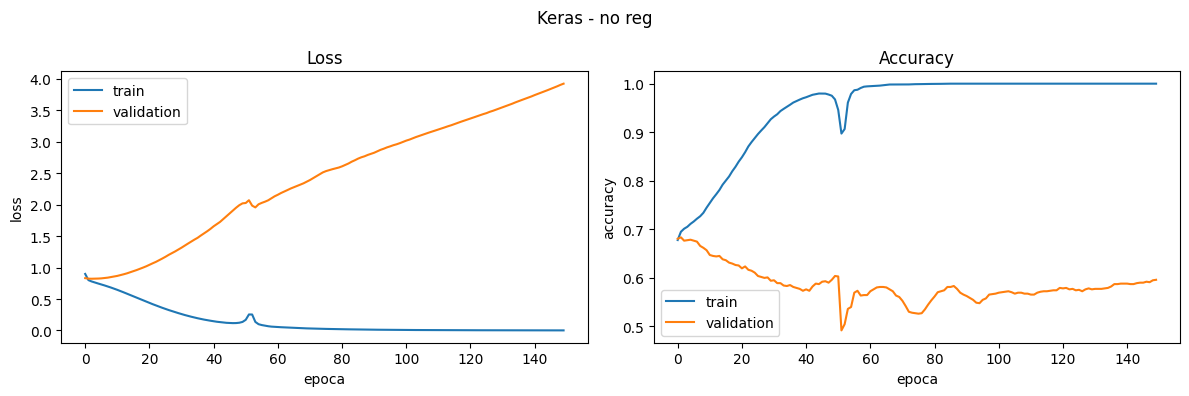

=== Keras - no reg - validation set ===
{'val_f1_macro': 0.275, 'val_balanced_acc': 0.276, 'val_roc_auc': 0.587, 'val_f1_0': 0.762, 'val_f1_1': 0.187, 'val_f1_2': 0.152, 'val_f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.733     0.794     0.762       700
           1      0.197     0.178     0.187       191
           2      0.181     0.132     0.152       114
           3      0.000     0.000     0.000        11

    accuracy                          0.595      1016
   macro avg      0.277     0.276     0.275      1016
weighted avg      0.562     0.595     0.577      1016



In [13]:
keras.utils.set_random_seed(RANDOM_STATE)
m_noreg, h_noreg, _, _ = train_and_eval('Keras - no reg', build_model())

**Commento** (metriche sul validation set: 1016 righe, di cui 11 della classe 3). È l'esempio di overfitting da manuale, ed è **il grafico più importante da mettere nel report**:
- la loss di training scende fino a ~0 e l'accuracy di training arriva al 100%: la rete memorizza il training set;
- la **validation loss è minima già all'epoca 3** e poi cresce costantemente fino a circa 3.9;
- l'accuracy di validazione scende dal 68% iniziale a circa il 60%.

Sul validation set la F1-macro è 0.275 e la ROC AUC 0.587 (la più bassa fra le varianti): una rete in overfitting predice le classi 1 e 2 "per caso" più spesso di una rete regolarizzata, ma le sue probabilità sono poco affidabili.

📌 **Report:** grafico loss/accuracy di questa cella + frase: *"senza regolarizzazione la validation loss raggiunge il minimo dopo 3 epoche e poi diverge, mentre la training loss tende a zero"*.

### 6.2 Early Stopping

Il training si interrompe quando la `val_loss` non migliora (di almeno `min_delta=1e-4`) per `patience=15`
epoche consecutive; con `restore_best_weights=True` si tengono i pesi dell'epoca migliore.
Si monitora la loss e non l'accuracy perché l'accuracy, dominata dalla classe 0, è poco sensibile.

Keras - early stopping: 18 epoche in 6s | val_loss minima all'epoca 3


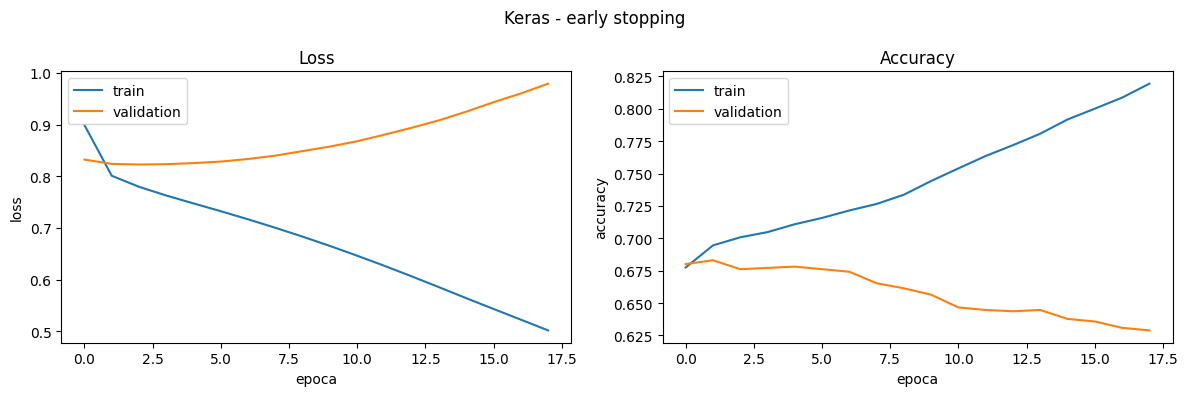

=== Keras - early stopping - validation set ===
{'val_f1_macro': 0.239, 'val_balanced_acc': 0.262, 'val_roc_auc': 0.672, 'val_f1_0': 0.814, 'val_f1_1': 0.054, 'val_f1_2': 0.087, 'val_f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.704     0.964     0.814       700
           1      0.182     0.031     0.054       191
           2      0.250     0.053     0.087       114
           3      0.000     0.000     0.000        11

    accuracy                          0.676      1016
   macro avg      0.284     0.262     0.239      1016
weighted avg      0.547     0.676     0.580      1016



In [14]:
keras.utils.set_random_seed(RANDOM_STATE)
m_es, h_es, _, _ = train_and_eval('Keras - early stopping', build_model(), callbacks=[early_stop()])

**Commento** (validation set). L'early stopping ferma il training all'epoca 18 e ripristina i pesi dell'epoca 3 (minimo della validation loss). Rispetto alla rete senza regolarizzazione:
- la **ROC AUC sale da 0.587 a 0.672**: le probabilità sono molto più informative;
- ma la **F1-macro scende da 0.275 a 0.239** e la recall della classe 1 crolla al 3%: la rete ferma così presto predice quasi sempre la classe 0 (recall 0.96).

Questo è il punto chiave: **evitare l'overfitting non basta**. Con la loss non pesata, il modello "ottimo" dal punto di vista della loss è quello che sta vicino alla classe maggioritaria. Serve anche gestire lo sbilanciamento (sezione 6.5).

📌 **Report:** la contrapposizione ROC AUC ↑ / F1-macro ↓ è il risultato più interessante di questa sezione.

### 6.3 Regolarizzazione L2 (con early stopping)

Keras - L2 (0.001): 22 epoche in 8s | val_loss minima all'epoca 9


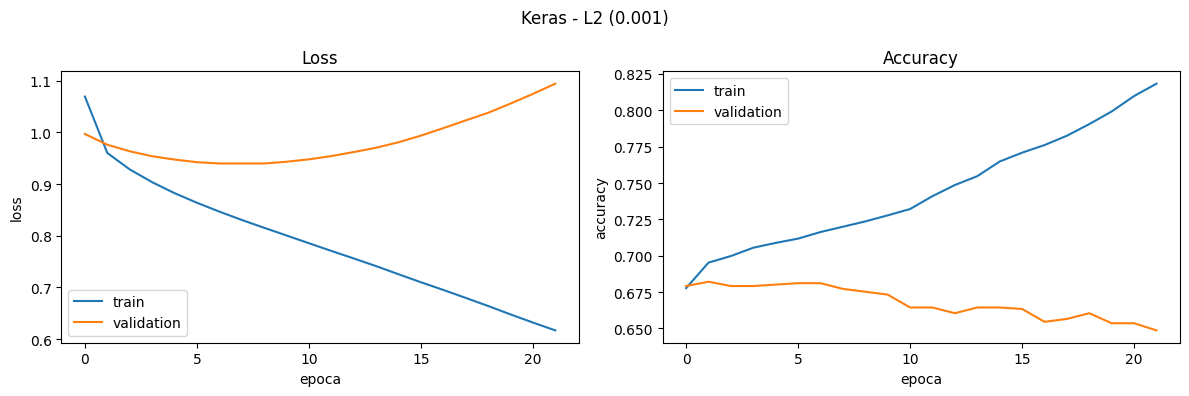

=== Keras - L2 (0.001) - validation set ===
{'val_f1_macro': 0.265, 'val_balanced_acc': 0.279, 'val_roc_auc': 0.679, 'val_f1_0': 0.821, 'val_f1_1': 0.087, 'val_f1_2': 0.152, 'val_f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.719     0.957     0.821       700
           1      0.250     0.052     0.087       191
           2      0.273     0.105     0.152       114
           3      0.000     0.000     0.000        11

    accuracy                          0.681      1016
   macro avg      0.310     0.279     0.265      1016
weighted avg      0.573     0.681     0.599      1016



In [15]:
L2_REG = 1e-3

keras.utils.set_random_seed(RANDOM_STATE)
m_l2, h_l2, _, _ = train_and_eval(f'Keras - L2 ({L2_REG})', build_model(reg_type='l2', reg=L2_REG),
                                  callbacks=[early_stop()])

### 6.4 Dropout (con early stopping)

Keras - dropout (0.3): 20 epoche in 8s | val_loss minima all'epoca 5


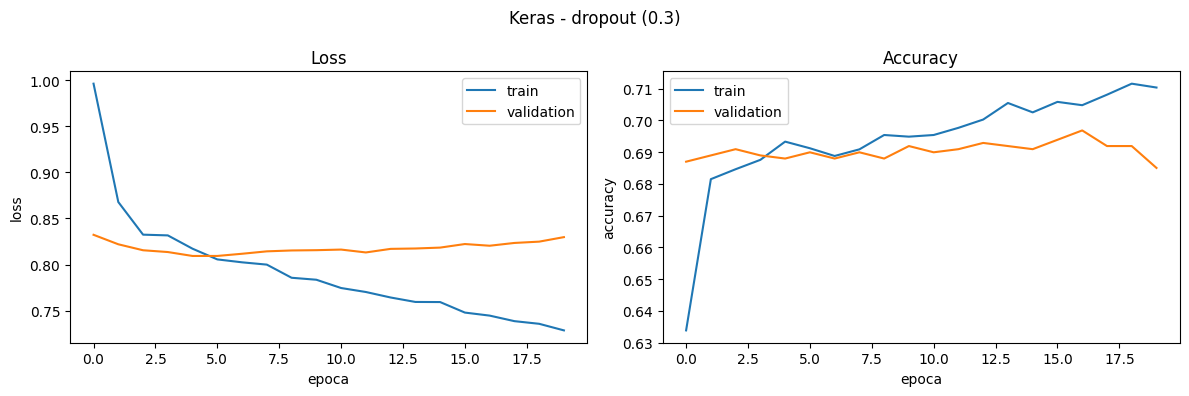

=== Keras - dropout (0.3) - validation set ===
{'val_f1_macro': 0.211, 'val_balanced_acc': 0.252, 'val_roc_auc': 0.686, 'val_f1_0': 0.817, 'val_f1_1': 0.01, 'val_f1_2': 0.017, 'val_f1_3': 0.0}
              precision    recall  f1-score   support

           0      0.692     0.996     0.817       700
           1      0.500     0.005     0.010       191
           2      0.143     0.009     0.017       114
           3      0.000     0.000     0.000        11

    accuracy                          0.688      1016
   macro avg      0.334     0.252     0.211      1016
weighted avg      0.587     0.688     0.566      1016



In [16]:
DROPOUT = 0.3

keras.utils.set_random_seed(RANDOM_STATE)
m_do, h_do, _, _ = train_and_eval(f'Keras - dropout ({DROPOUT})', build_model(dropout=DROPOUT),
                                  callbacks=[early_stop()])

**Commento** (validation set).
- **L2 (1e-3)**: sposta il minimo della validation loss dall'epoca 3 all'epoca 9 e rallenta la divergenza (curva verde nel grafico di confronto). ROC AUC 0.679 e F1-macro 0.265, meglio del solo early stopping (0.239), ma la recall della classe 1 resta al 5%.
- **Dropout (0.3)**: la validation loss resta la più bassa e piatta (curva rossa), quindi è la regolarizzazione più efficace contro l'overfitting, e ha la ROC AUC più alta (0.686). Però la rete predice quasi solo la classe 0 (recall 99.6%) e la F1-macro è la peggiore (0.211).

Entrambe le tecniche riducono l'overfitting, ma senza pesi di classe spingono il modello verso la classe maggioritaria: **più la rete è regolarizzata, più si avvicina al Dummy in termini di predizioni**.

📌 **Report:** il grafico di confronto delle validation loss (sezione 6.10) riassume L2 e Dropout meglio delle singole curve.

### 6.5 Dropout + class weight

Keras accetta `class_weight`: gli errori sulle classi rare pesano di più nella loss, in modo inversamente
proporzionale alla frequenza della classe (stessa logica di `class_weight='balanced'` in LR e SVM).

Questa variante è il **riferimento** per gli esperimenti 6.6–6.9.

Pesi: {0: 0.36, 1: 1.33, 2: 2.22, 3: 24.37}
Keras - dropout + class weight: 20 epoche in 8s | val_loss minima all'epoca 5


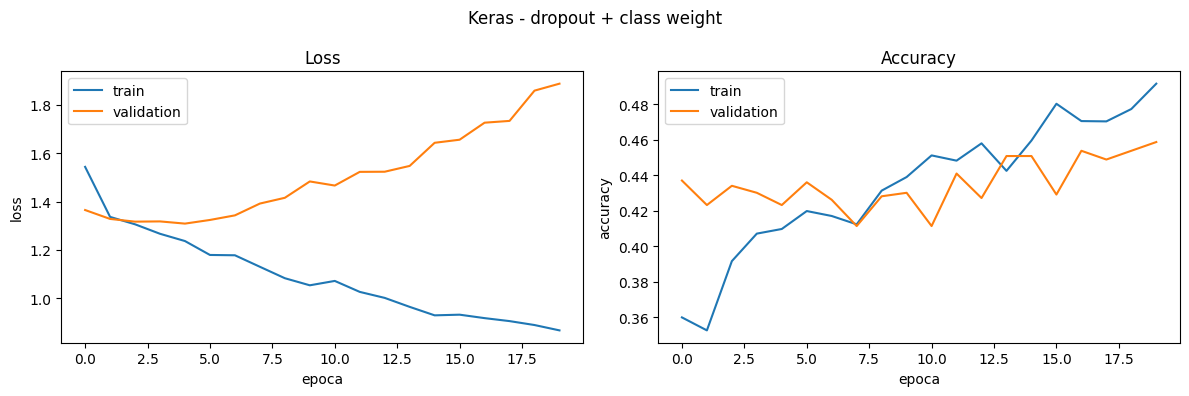

=== Keras - dropout + class weight - validation set ===
{'val_f1_macro': 0.276, 'val_balanced_acc': 0.387, 'val_roc_auc': 0.642, 'val_f1_0': 0.627, 'val_f1_1': 0.183, 'val_f1_2': 0.246, 'val_f1_3': 0.05}
              precision    recall  f1-score   support

           0      0.823     0.506     0.627       700
           1      0.194     0.173     0.183       191
           2      0.198     0.325     0.246       114
           3      0.026     0.545     0.050        11

    accuracy                          0.423      1016
   macro avg      0.310     0.387     0.276      1016
weighted avg      0.626     0.423     0.494      1016



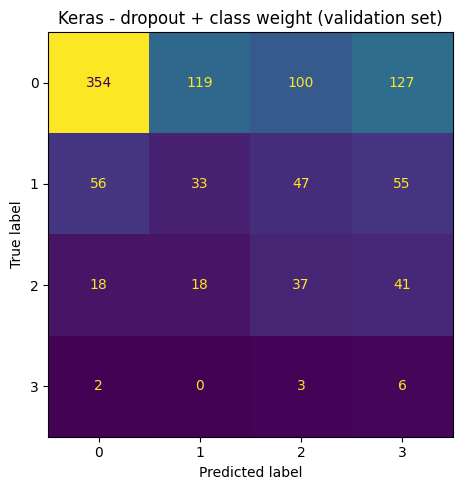

In [17]:
pesi = compute_class_weight('balanced', classes=np.array(CLASSI), y=y_tr)
class_weight = dict(zip(CLASSI, pesi))
print('Pesi:', {k: round(float(v), 2) for k, v in class_weight.items()})

keras.utils.set_random_seed(RANDOM_STATE)
m_cw, h_cw, y_pred_cw, y_prob_cw = train_and_eval(
    'Keras - dropout + class weight', build_model(dropout=DROPOUT),
    callbacks=[early_stop()], class_weight=class_weight)
plot_confusion(y_pred_cw, 'Keras - dropout + class weight (validation set)', y_true=y_val)

**Commento** (validation set). Con i pesi delle classi (classe 0: 0.36, classe 3: 24.4), applicati sia alla loss di training sia a quella di validazione, il comportamento cambia completamente:
- la **balanced accuracy sale da 0.252 (dropout senza pesi) a 0.387** e la F1-macro da 0.211 a **0.276**;
- la recall della classe 2 passa dall'1% al **32%**, quella della classe 1 al 17%, e la rete individua 6 degli 11 casi della classe 3 (recall 55%, ma con precision del 3%);
- l'accuracy scende a 0.423, perché metà dei soggetti della classe 0 viene assegnata alle classi superiori.

**Overfitting con la loss pesata.** Il grafico mostra che, misurata con lo stesso obiettivo pesato del training, anche questa rete va in overfitting presto: la validation loss è minima all'epoca 5 e poi risale (da 1.31 a quasi 1.9), mentre la training loss continua a scendere. Il motivo è che i pesi amplificano gli errori sui pochi esempi delle classi rare (70 esempi di classe 3 nel training con peso 24), che la rete impara presto a memorizzare. L'early stopping sulla validation loss pesata interrompe il training al momento giusto.

📌 **Report:** il grafico loss train/validation di questa cella e la confusion matrix sul validation set, confrontata con quella della rete senza pesi.

### 6.6 Batch Normalization

Un layer `BatchNormalization` dopo ogni hidden layer (prima dell'attivazione) normalizza gli input del layer
successivo su ogni mini-batch: rende il training più stabile e veloce, e ha un leggero effetto regolarizzante.

Keras - cw + batch norm: 19 epoche in 9s | val_loss minima all'epoca 4


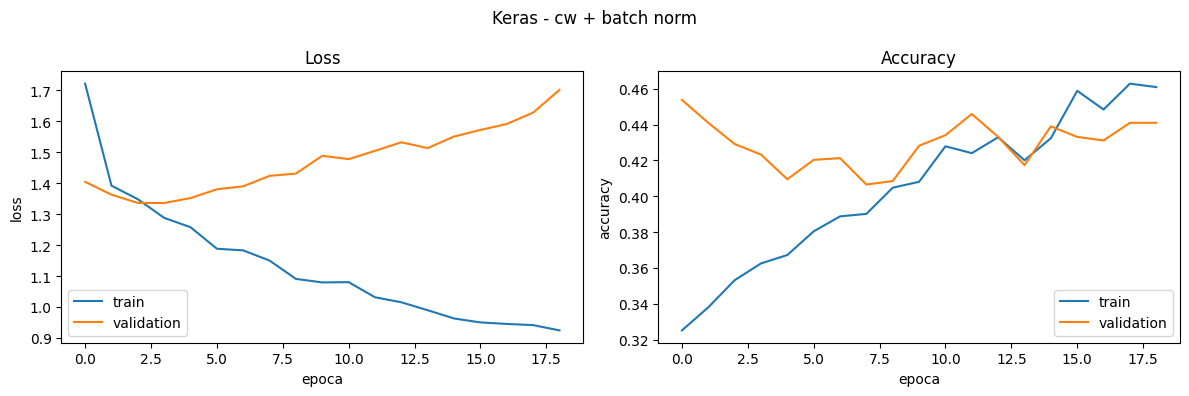

=== Keras - cw + batch norm - validation set ===
{'val_f1_macro': 0.283, 'val_balanced_acc': 0.386, 'val_roc_auc': 0.641, 'val_f1_0': 0.61, 'val_f1_1': 0.197, 'val_f1_2': 0.27, 'val_f1_3': 0.056}
              precision    recall  f1-score   support

           0      0.819     0.486     0.610       700
           1      0.186     0.209     0.197       191
           2      0.205     0.395     0.270       114
           3      0.030     0.455     0.056        11

    accuracy                          0.423      1016
   macro avg      0.310     0.386     0.283      1016
weighted avg      0.623     0.423     0.488      1016



In [18]:
keras.utils.set_random_seed(RANDOM_STATE)
m_bn, h_bn, _, _ = train_and_eval(
    'Keras - cw + batch norm', build_model(dropout=DROPOUT, batchnorm=True),
    callbacks=[early_stop()], class_weight=class_weight)

### 6.7 Regolarizzazione L1

La penalità L1 (somma dei valori assoluti dei pesi) spinge molti pesi esattamente a zero: è una forma di
selezione implicita delle feature, potenzialmente utile con 68 feature e un segnale debole.

Keras - cw + L1 (0.001): 43 epoche in 15s | val_loss minima all'epoca 28


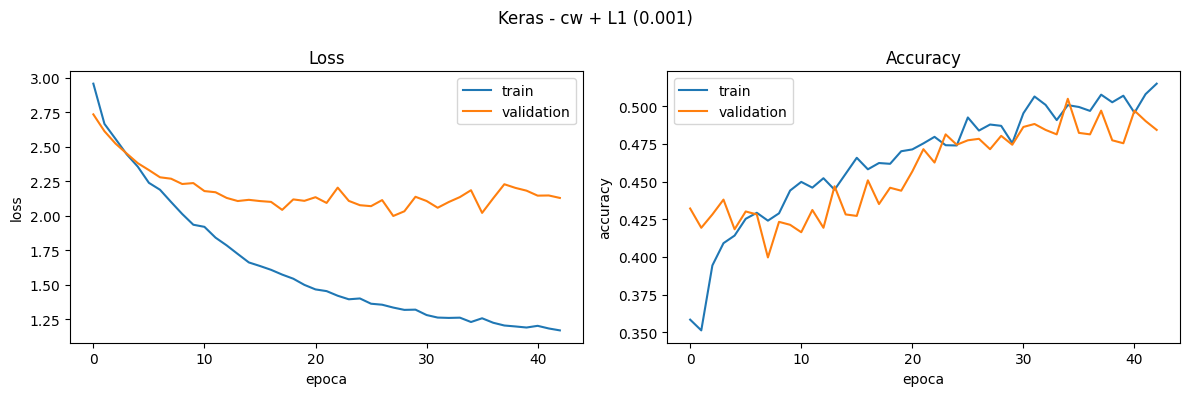

=== Keras - cw + L1 (0.001) - validation set ===
{'val_f1_macro': 0.292, 'val_balanced_acc': 0.377, 'val_roc_auc': 0.659, 'val_f1_0': 0.66, 'val_f1_1': 0.16, 'val_f1_2': 0.29, 'val_f1_3': 0.057}
              precision    recall  f1-score   support

           0      0.817     0.554     0.660       700
           1      0.195     0.136     0.160       191
           2      0.198     0.544     0.290       114
           3      0.032     0.273     0.057        11

    accuracy                          0.471      1016
   macro avg      0.310     0.377     0.292      1016
weighted avg      0.622     0.471     0.518      1016



In [19]:
L1_REG = 1e-3

keras.utils.set_random_seed(RANDOM_STATE)
m_l1, h_l1, _, _ = train_and_eval(
    f'Keras - cw + L1 ({L1_REG})', build_model(dropout=DROPOUT, reg_type='l1', reg=L1_REG),
    callbacks=[early_stop()], class_weight=class_weight)

### 6.8 SGD con momentum

Discesa del gradiente stocastica classica con **momentum** (vista a lezione) al posto di Adam.
Con SGD serve un learning rate più alto (1e-2): con 1e-3 la convergenza sarebbe molto lenta.

Keras - cw + SGD momentum 0.9: 19 epoche in 7s | val_loss minima all'epoca 4


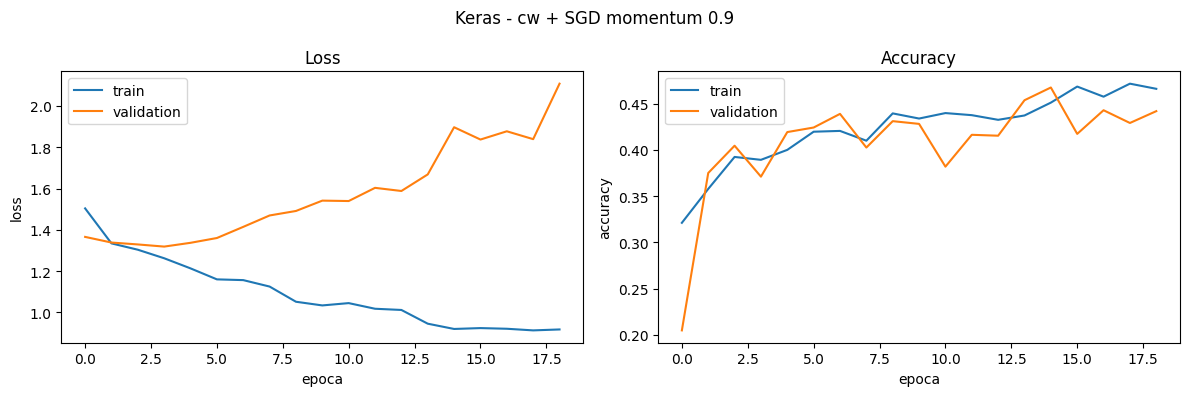

=== Keras - cw + SGD momentum 0.9 - validation set ===
{'val_f1_macro': 0.247, 'val_balanced_acc': 0.355, 'val_roc_auc': 0.63, 'val_f1_0': 0.584, 'val_f1_1': 0.116, 'val_f1_2': 0.253, 'val_f1_3': 0.034}
              precision    recall  f1-score   support

           0      0.827     0.451     0.584       700
           1      0.165     0.089     0.116       191
           2      0.204     0.333     0.253       114
           3      0.017     0.545     0.034        11

    accuracy                          0.371      1016
   macro avg      0.303     0.355     0.247      1016
weighted avg      0.624     0.371     0.453      1016



In [20]:
keras.utils.set_random_seed(RANDOM_STATE)
m_sgd, h_sgd, _, _ = train_and_eval(
    'Keras - cw + SGD momentum 0.9',
    build_model(dropout=DROPOUT, optimizer='sgd', lr=1e-2, momentum=0.9),
    callbacks=[early_stop()], class_weight=class_weight)

### 6.9 Learning rate decrescente

`ReduceLROnPlateau` dimezza il learning rate quando la `val_loss` non migliora per 5 epoche: con passi più
piccoli la rete può avvicinarsi meglio al minimo prima che intervenga l'early stopping (patience 15).

Keras - cw + ReduceLROnPlateau: 20 epoche in 8s | val_loss minima all'epoca 5


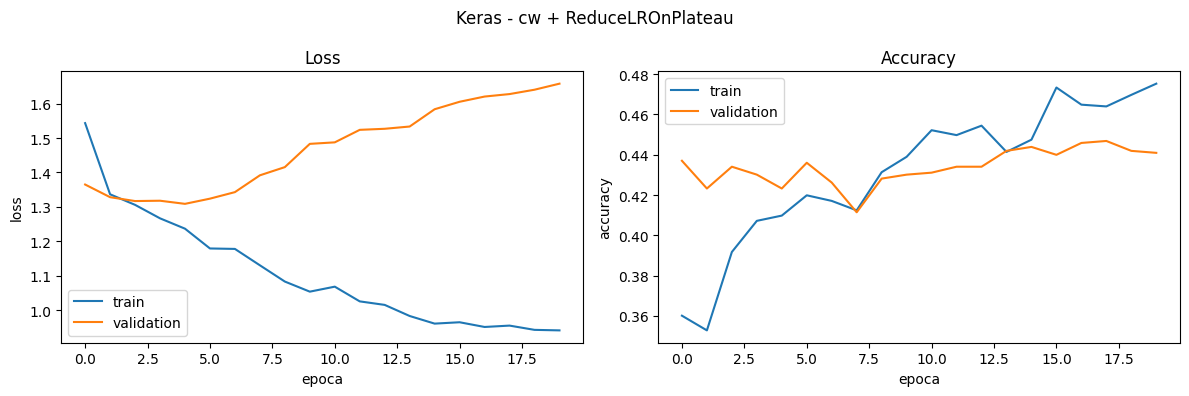

=== Keras - cw + ReduceLROnPlateau - validation set ===
{'val_f1_macro': 0.276, 'val_balanced_acc': 0.387, 'val_roc_auc': 0.642, 'val_f1_0': 0.627, 'val_f1_1': 0.183, 'val_f1_2': 0.246, 'val_f1_3': 0.05}
              precision    recall  f1-score   support

           0      0.823     0.506     0.627       700
           1      0.194     0.173     0.183       191
           2      0.198     0.325     0.246       114
           3      0.026     0.545     0.050        11

    accuracy                          0.423      1016
   macro avg      0.310     0.387     0.276      1016
weighted avg      0.626     0.423     0.494      1016



In [21]:
def reduce_lr():
    return ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5)

keras.utils.set_random_seed(RANDOM_STATE)
m_rlr, h_rlr, _, _ = train_and_eval(
    'Keras - cw + ReduceLROnPlateau', build_model(dropout=DROPOUT),
    callbacks=[early_stop(), reduce_lr()], class_weight=class_weight)

**Commento sulle varianti 6.6–6.9**, tutte confrontate sul validation set con la variante 6.5 (F1-macro 0.276):

| Variante | F1-macro val | Bal. acc. val | ROC AUC val | Epoche (minimo val_loss) |
|---|---|---|---|---|
| riferimento: dropout + class weight | 0.276 | 0.387 | 0.642 | 20 (5) |
| + Batch Normalization | 0.283 | 0.386 | 0.641 | 19 (4) |
| + L1 (1e-3) | **0.292** | 0.377 | **0.659** | 43 (28) |
| SGD + momentum 0.9 | 0.247 | 0.355 | 0.630 | 19 (4) |
| + ReduceLROnPlateau | 0.276 | 0.387 | 0.642 | 20 (5) |

- **L1** (aggiunta alla rete di riferimento, che non ha altra regolarizzazione sui pesi) è la variante con F1-macro e ROC AUC più alte sul validation set (+0.016 di F1-macro). Converge molto più lentamente (minimo all'epoca 28 invece che alla 5): la penalità L1 rallenta l'adattamento ai dati, e la rete continua a migliorare più a lungo prima di andare in overfitting. La sua validation loss è su una scala più alta (curva verde) perché la loss riportata da Keras include la penalità di regolarizzazione.
- **Batch Normalization**: +0.007 di F1-macro, con le altre metriche invariate. Non cambia il comportamento del training (minimo all'epoca 4 invece che alla 5).
- **SGD con momentum** è la variante peggiore (−0.029): la curva è più rumorosa e diverge più in fretta dopo il minimo (passi meno adattivi di Adam).
- **ReduceLROnPlateau** non cambia nulla, e c'è un motivo preciso: il learning rate verrebbe dimezzato all'epoca 10 (5 epoche senza miglioramento dopo il minimo all'epoca 5), ma l'early stopping ripristina i pesi dell'epoca 5, **prima** della riduzione. Il modello finale è quindi identico.
- **Cautela:** il validation set ha 1016 righe e solo 11 esempi della classe 3; differenze di 0.01–0.02 di F1-macro sono dell'ordine della variabilità attesa (nella sezione 9 si vede che sul test set l'ordine delle varianti è diverso). Inoltre il validation set è lo stesso usato dall'early stopping per scegliere l'epoca, quindi queste metriche sono leggermente ottimistiche (in modo simile per tutte le varianti con early stopping). L'unico effetto netto è quello negativo di SGD.

📌 **Report:** questa tabella e il grafico di destra della sezione 6.10. Conclusione: *una volta gestiti overfitting (early stopping) e sbilanciamento (class weight), le tecniche di ottimizzazione aggiuntive danno differenze piccole, non distinguibili dalla variabilità del validation set; solo SGD peggiora in modo netto.*

### 6.10 Confronto delle varianti Keras

Confronto sul **validation set** (il test set viene usato solo nella sezione 9).

In [22]:
tab_keras_val = pd.DataFrame(risultati_val).set_index('modello')
tab_keras_val.round(3)

,val_f1_macro,val_balanced_acc,val_roc_auc,epoche,epoca_migliore,val_f1_0,val_f1_1,val_f1_2,val_f1_3
modello,,,,,,,,,
Keras - no reg,0.275,0.276,0.587,150,3,0.762,0.187,0.152,0.000
Keras - early stopping,0.239,0.262,0.672,18,3,0.814,0.054,0.087,0.000
Keras - L2 (0.001),0.265,0.279,0.679,22,9,0.821,0.087,0.152,0.000
Keras - dropout (0.3),0.211,0.252,0.686,20,5,0.817,0.010,0.017,0.000
Keras - dropout + class weight,0.276,0.387,0.642,20,5,0.627,0.183,0.246,0.050
Keras - cw + batch norm,0.283,0.386,0.641,19,4,0.610,0.197,0.270,0.056
Keras - cw + L1 (0.001),0.292,0.377,0.659,43,28,0.660,0.160,0.290,0.057
Keras - cw + SGD momentum 0.9,0.247,0.355,0.630,19,4,0.584,0.116,0.253,0.034
Keras - cw + ReduceLROnPlateau,0.276,0.387,0.642,20,5,0.627,0.183,0.246,0.050


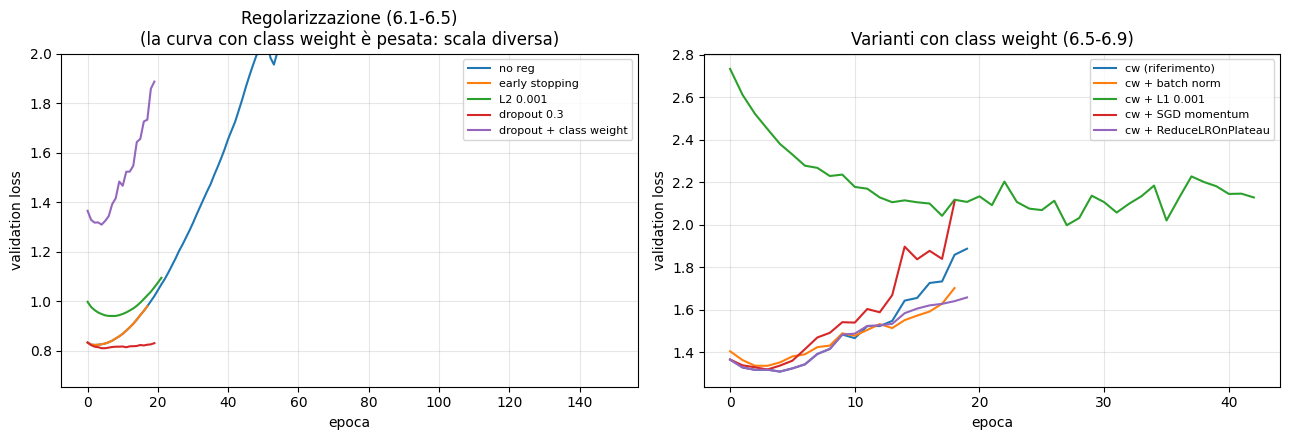

In [23]:
# Curve di validation loss a confronto (grafici utili per il report)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for nome, h in [('no reg', h_noreg), ('early stopping', h_es), (f'L2 {L2_REG}', h_l2),
                (f'dropout {DROPOUT}', h_do), ('dropout + class weight', h_cw)]:
    axes[0].plot(h.history['val_loss'], label=nome)
axes[0].set_ylim(top=2); axes[0].set_title('Regolarizzazione (6.1-6.5)\n(la curva con class weight è pesata: scala diversa)')

for nome, h in [('cw (riferimento)', h_cw), ('cw + batch norm', h_bn), (f'cw + L1 {L1_REG}', h_l1),
                ('cw + SGD momentum', h_sgd), ('cw + ReduceLROnPlateau', h_rlr)]:
    axes[1].plot(h.history['val_loss'], label=nome)
axes[1].set_title('Varianti con class weight (6.5-6.9)')

for ax in axes:
    ax.set_xlabel('epoca'); ax.set_ylabel('validation loss'); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Commento.**
- **Grafico di sinistra** (sezioni 6.1–6.5): **no reg** (blu) diverge dopo poche epoche → overfitting; **early stopping / L2 / dropout** fermano il training vicino al minimo, con L2 che sposta il minimo più avanti (epoca 9) e dropout che tiene la curva più bassa e piatta. La curva **dropout + class weight** (viola) è calcolata con la loss pesata, quindi è su un'altra scala e non va confrontata in valore assoluto con le altre: va letta solo nella forma (minimo all'epoca 5, poi risale).
- **Grafico di destra** (sezioni 6.5–6.9, tutte con loss pesata): il riferimento, Batch Normalization, SGD e ReduceLROnPlateau hanno lo stesso andamento, con il minimo intorno all'epoca 4-5 e poi una risalita (più rapida per SGD). L1 parte più in alto (la loss include la penalità) ma scende lentamente fino all'epoca 28: è l'unica variante con un training più lungo.

📌 **Report — risposta alla domanda delle guidelines** *"what are the parameter sets or the convergence criteria which avoid overfitting?"*: early stopping sulla validation loss (con `restore_best_weights` e `min_delta`, e con la loss di validazione pesata come quella di training), dropout, L2 o L1. Ma su questo dataset evitare l'overfitting non basta: senza `class_weight` le reti regolarizzate collassano sulla classe 0.

## 7. Confronto fra architetture

Tre reti di dimensione crescente, tutte con la stessa ricetta di training (dropout 0.3, class weight,
early stopping), per vedere quanto conta la **capacità** del modello. Il confronto è sul validation set.

| Rete | Hidden layer |
|---|---|
| piccola | 16 |
| media | 64 - 32 |
| grande | 256 - 128 - 64 |

Rete piccola (16,): 1,172 parametri
Keras - rete piccola (16,): 27 epoche in 9s | val_loss minima all'epoca 12


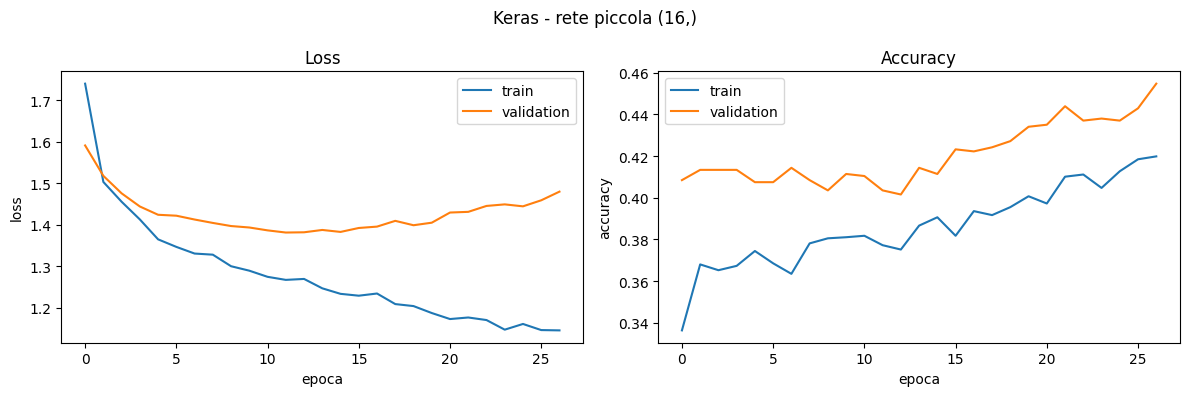

=== Keras - rete piccola (16,) - validation set ===
{'val_f1_macro': 0.263, 'val_balanced_acc': 0.292, 'val_roc_auc': 0.614, 'val_f1_0': 0.59, 'val_f1_1': 0.248, 'val_f1_2': 0.195, 'val_f1_3': 0.019}
              precision    recall  f1-score   support

           0      0.796     0.469     0.590       700
           1      0.227     0.272     0.248       191
           2      0.162     0.246     0.195       114
           3      0.010     0.182     0.019        11

    accuracy                          0.404      1016
   macro avg      0.299     0.292     0.263      1016
weighted avg      0.609     0.404     0.475      1016

Rete media (64, 32): 6,628 parametri
Keras - rete media (64, 32): 20 epoche in 7s | val_loss minima all'epoca 5


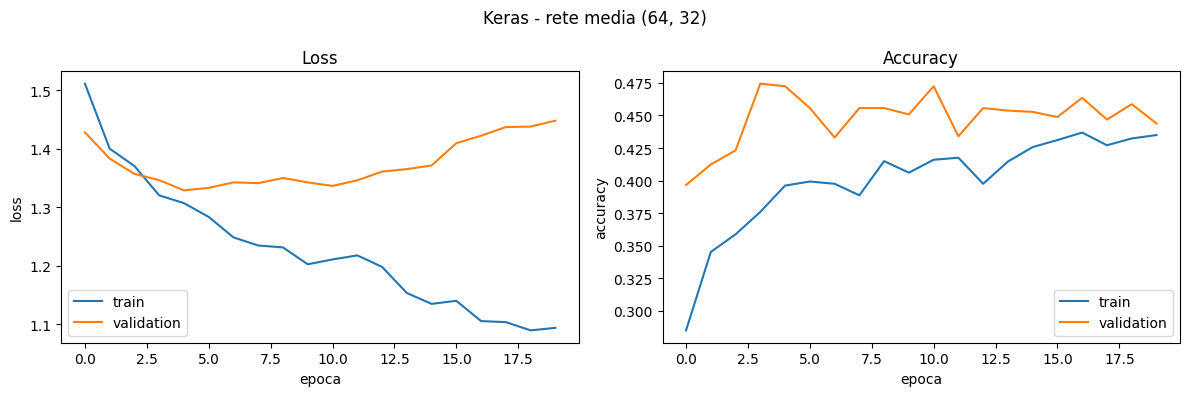

=== Keras - rete media (64, 32) - validation set ===
{'val_f1_macro': 0.289, 'val_balanced_acc': 0.347, 'val_roc_auc': 0.622, 'val_f1_0': 0.671, 'val_f1_1': 0.204, 'val_f1_2': 0.245, 'val_f1_3': 0.038}
              precision    recall  f1-score   support

           0      0.808     0.573     0.671       700
           1      0.230     0.183     0.204       191
           2      0.186     0.360     0.245       114
           3      0.020     0.273     0.038        11

    accuracy                          0.472      1016
   macro avg      0.311     0.347     0.289      1016
weighted avg      0.621     0.472     0.528      1016

Rete grande (256, 128, 64): 59,076 parametri
Keras - rete grande (256, 128, 64): 18 epoche in 6s | val_loss minima all'epoca 3


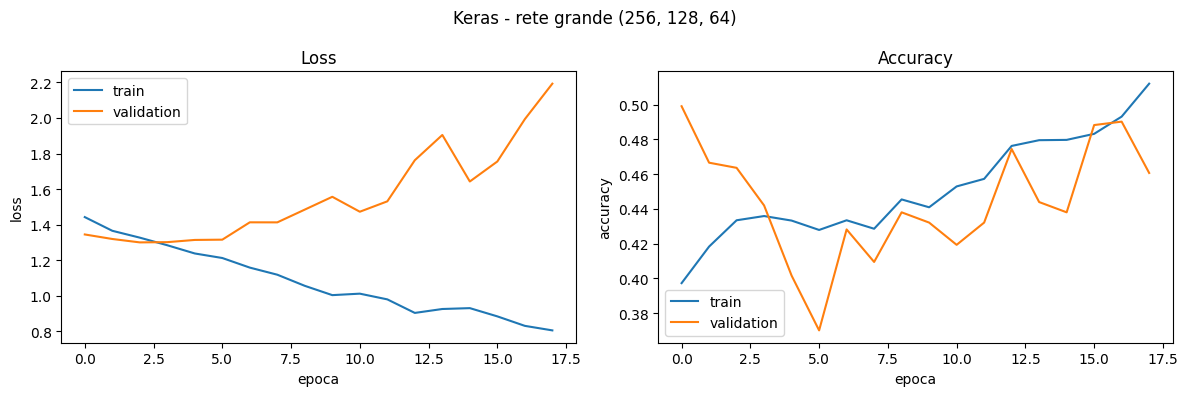

=== Keras - rete grande (256, 128, 64) - validation set ===
{'val_f1_macro': 0.297, 'val_balanced_acc': 0.377, 'val_roc_auc': 0.671, 'val_f1_0': 0.667, 'val_f1_1': 0.175, 'val_f1_2': 0.309, 'val_f1_3': 0.035}
              precision    recall  f1-score   support

           0      0.833     0.556     0.667       700
           1      0.231     0.141     0.175       191
           2      0.236     0.447     0.309       114
           3      0.019     0.364     0.035        11

    accuracy                          0.464      1016
   macro avg      0.330     0.377     0.297      1016
weighted avg      0.644     0.464     0.527      1016



In [24]:
ARCHITETTURE = {'piccola': (16,), 'media': (64, 32), 'grande': (256, 128, 64)}
h_arch = {}

for nome, hidden in ARCHITETTURE.items():
    keras.utils.set_random_seed(RANDOM_STATE)
    model = build_model(hidden=hidden, dropout=DROPOUT)
    print(f'Rete {nome} {hidden}: {model.count_params():,} parametri')
    _, h_arch[nome], _, _ = train_and_eval(f'Keras - rete {nome} {hidden}', model,
                                           callbacks=[early_stop()], class_weight=class_weight)

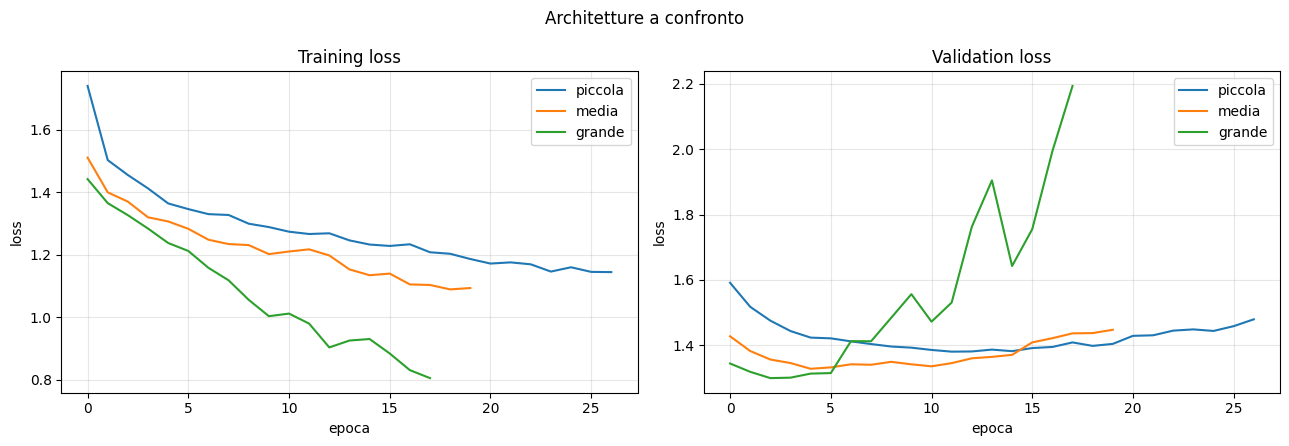

,val_f1_macro,val_balanced_acc,val_roc_auc,epoche,epoca_migliore,val_f1_0,val_f1_1,val_f1_2,val_f1_3
modello,,,,,,,,,
"Keras - rete piccola (16,)",0.263,0.292,0.614,27,12,0.590,0.248,0.195,0.019
"Keras - rete media (64, 32)",0.289,0.347,0.622,20,5,0.671,0.204,0.245,0.038
"Keras - rete grande (256, 128, 64)",0.297,0.377,0.671,18,3,0.667,0.175,0.309,0.035


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for nome, h in h_arch.items():
    axes[0].plot(h.history['loss'], label=nome)
    axes[1].plot(h.history['val_loss'], label=nome)
axes[0].set_title('Training loss'); axes[1].set_title('Validation loss')
for ax in axes:
    ax.set_xlabel('epoca'); ax.set_ylabel('loss'); ax.legend(); ax.grid(alpha=.3)
plt.suptitle('Architetture a confronto'); plt.tight_layout(); plt.show()

# Confronto sul validation set
pd.DataFrame([r for r in risultati_val if 'rete' in r['modello']]).set_index('modello').round(3)

**Commento** (validation set).

| Rete | Parametri | Epoche (minimo val_loss) | F1-macro val | Bal. acc. val | ROC AUC val |
|---|---|---|---|---|---|
| piccola (16) | 1.172 | 27 (12) | 0.263 | 0.292 | 0.614 |
| media (64-32) | 6.628 | 20 (5) | 0.289 | 0.347 | 0.622 |
| grande (256-128-64) | 59.076 | 18 (3) | **0.297** | **0.377** | **0.671** |

- Il grafico mostra chiaramente il ruolo della **capacità**: la rete **grande** abbassa la training loss molto più velocemente, ma la validation loss è minima già all'epoca 3 e poi esplode (fino a circa 2.2) → **overfitting rapidissimo**. La rete **piccola** ha la training loss più alta e la validation loss scende lentamente fino all'epoca 12 → impara poco, **leggero underfitting**. La rete **media** sta nel mezzo (minimo all'epoca 5).
- Sul validation set la rete grande ottiene la F1-macro più alta: grazie all'early stopping con `restore_best_weights` si usano i pesi dell'epoca 3, prima dell'overfitting. L'early stopping "neutralizza" quindi l'eccesso di capacità.
- Le differenze di F1-macro fra le tre reti (0.263–0.297) vanno lette con cautela: sul test set (sezione 9) l'ordine non è lo stesso (piccola 0.297, grande 0.296, media 0.294). **La capacità determina quanto velocemente la rete va in overfitting, non quanto bene generalizza una volta fermata al momento giusto.**

📌 **Report:** tabella + grafico training/validation loss delle tre architetture: è una delle figure migliori per spiegare overfitting e underfitting.

## 8. Rete in Keras: hyper-parameter tuning

Tuning con `KerasClassifier` di **scikeras**, che rende la rete compatibile con `Pipeline` e
`RandomizedSearchCV`. (Nel notebook di lezione si usa `build_fn=`: nelle versioni recenti di scikeras il
parametro si chiama `model=`.)

Si usa la stessa 5-fold stratificata del tuning dell'MLP, così i due tuning sono confrontabili.
Ogni configurazione è addestrata con early stopping (`patience=10`, `min_delta=1e-4`) su un 15% del training del fold.

**Validazione pesata anche qui.** `KerasClassifier` di scikeras converte `class_weight` in pesi per esempio
(`sample_weight`), e Keras divide i pesi insieme ai dati quando crea il validation set con `validation_split`:
la loss di validazione usata dall'early stopping è quindi pesata come quella di training, coerentemente con la
sezione 6.

**Scelta della griglia.** La griglia contiene architettura, attivazione, L2, dropout, learning rate, batch size e
`class_weight`, con ottimizzatore Adam. Le tecniche delle sezioni 6.6–6.9 **non sono incluse**:
- SGD con momentum ha peggiorato nettamente la F1-macro sul validation set (−0.029) e ReduceLROnPlateau non ha
  avuto alcun effetto;
- Batch Normalization (+0.007) e L1 (+0.016) hanno dato valori un po' più alti, ma le differenze sono dell'ordine
  della variabilità di un validation set di 1016 righe (11 esempi della classe 3).

Aggiungerle avrebbe allargato molto lo spazio di ricerca, che a parità di configurazioni provate verrebbe esplorato
peggio (o richiederebbe tempi di esecuzione molto più lunghi). È un **limite** da dichiarare: con più risorse
L1 e Batch Normalization andrebbero valutate in cross-validation.

**Scelte per contenere i tempi** (da citare nel report): al massimo 100 epoche, `batch_size` 64 o 128,
10 configurazioni. Con l'early stopping quasi tutte le configurazioni si fermano molto prima delle 100 epoche.

In [26]:
N_ITER_KERAS = 10   # configurazioni provate (10 x 5 fold = 50 addestramenti)

# scikeras richiede che gli iperparametri compaiano esplicitamente nella firma della funzione
def build_model_sk(meta, hidden, activation, l2_reg, dropout, lr):
    return make_net(meta['n_features_in_'], meta['n_classes_'], hidden=hidden, activation=activation,
                    reg_type='l2', reg=l2_reg, dropout=dropout, optimizer='adam', lr=lr)

keras_clf = KerasClassifier(
    model=build_model_sk, epochs=100, batch_size=128, verbose=0, validation_split=0.15,
    callbacks=[EarlyStopping(monitor='val_loss', patience=10, min_delta=1e-4, restore_best_weights=True)],
    random_state=RANDOM_STATE,
    # valori di default degli iperparametri della rete (sovrascritti dalla ricerca)
    model__hidden=(64,), model__activation='relu', model__l2_reg=0.0, model__dropout=0.0, model__lr=1e-3)

param_keras = {
    'clf__model__hidden': [(32,), (64,), (128,), (64, 32), (128, 64)],
    'clf__model__activation': ['relu', 'tanh'],
    'clf__model__l2_reg': [0.0, 1e-4, 1e-3, 1e-2],
    'clf__model__dropout': [0.0, 0.2, 0.4],
    'clf__model__lr': [1e-3, 1e-2],
    'clf__batch_size': [64, 128],
    'clf__class_weight': [None, 'balanced'],
}

rs_keras = RandomizedSearchCV(
    Pipeline([('prep', clone(preprocessor)), ('clf', keras_clf)]),
    param_keras, n_iter=N_ITER_KERAS, scoring='f1_macro',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=1, verbose=1)

t0 = time.time()
rs_keras.fit(X_train, y_train)
print(f'Ricerca completata in {time.time() - t0:.0f}s')
print('Migliori parametri:', rs_keras.best_params_)
print('F1-macro in CV:', round(rs_keras.best_score_, 4))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Ricerca completata in 295s
Migliori parametri: {'clf__model__lr': 0.001, 'clf__model__l2_reg': 0.01, 'clf__model__hidden': (64,), 'clf__model__dropout': 0.4, 'clf__model__activation': 'relu', 'clf__class_weight': 'balanced', 'clf__batch_size': 64}
F1-macro in CV: 0.3115


In [27]:
cols = ['param_' + p for p in param_keras] + ['mean_test_score', 'std_test_score', 'rank_test_score']
tab_keras_cv = (pd.DataFrame(rs_keras.cv_results_)[cols]
                .rename(columns=lambda c: c.replace('param_clf__model__', '').replace('param_clf__', ''))
                .sort_values('rank_test_score'))
tab_keras_cv['class_weight'] = tab_keras_cv['class_weight'].fillna('None')
tab_keras_cv.round(4)

,hidden,activation,l2_reg,dropout,lr,batch_size,class_weight,mean_test_score,std_test_score,rank_test_score
7,"(64,)",relu,0.0100,0.4,0.001,64,balanced,0.3115,0.0129,1
2,"(64, 32)",relu,0.0100,0.4,0.001,64,balanced,0.3005,0.0208,2
4,"(32,)",tanh,0.0001,0.4,0.010,128,balanced,0.2961,0.0201,3
0,"(128, 64)",relu,0.0010,0.4,0.001,128,balanced,0.2945,0.0110,4
9,"(128, 64)",tanh,0.0100,0.0,0.001,128,balanced,0.2928,0.0137,5
3,"(64,)",tanh,0.0010,0.2,0.010,128,balanced,0.2761,0.0276,6
5,"(128,)",relu,0.0010,0.0,0.010,64,balanced,0.2722,0.0207,7
1,"(128, 64)",tanh,0.0010,0.4,0.010,64,balanced,0.2663,0.0196,8
6,"(64,)",tanh,0.0100,0.4,0.010,64,None,0.2309,0.0064,9
8,"(32,)",relu,0.0100,0.4,0.001,64,None,0.2300,0.0117,10


In [28]:
# Effetto di class_weight in CV
tab_keras_cv.groupby('class_weight')['mean_test_score'].agg(['mean', 'max', 'count']).round(4)

,mean,max,count
class_weight,,,
None,0.2305,0.2309,2
balanced,0.2888,0.3115,8


=== Keras tuned ===
{'accuracy': 0.496, 'balanced_acc': 0.379, 'f1_macro': 0.32, 'roc_auc': 0.674, 'f1_0': 0.662, 'f1_1': 0.264, 'f1_2': 0.309, 'f1_3': 0.047}
              precision    recall  f1-score   support

           0      0.792     0.569     0.662      1167
           1      0.261     0.268     0.264       317
           2      0.233     0.458     0.309       190
           3      0.026     0.222     0.047        18

    accuracy                          0.496      1692
   macro avg      0.328     0.379     0.320      1692
weighted avg      0.622     0.496     0.542      1692



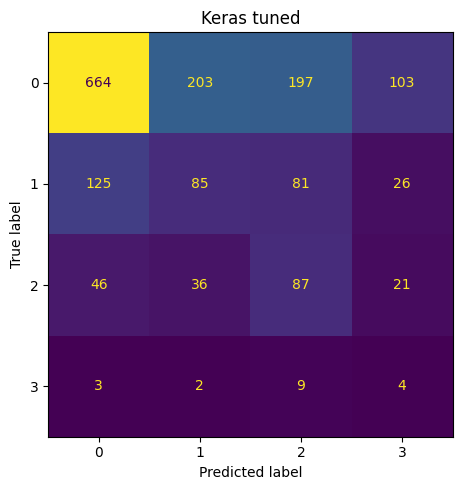

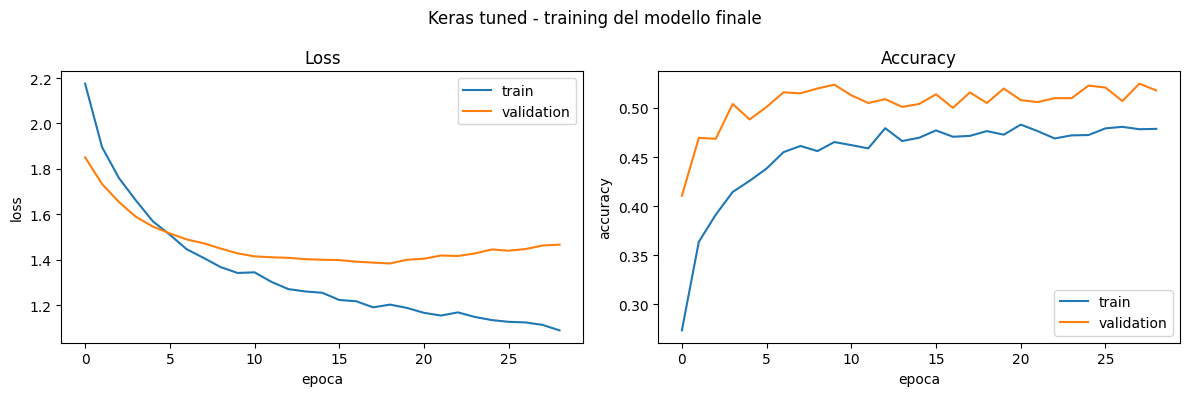

In [29]:
keras_best = rs_keras.best_estimator_
risultati.append(valuta('Keras tuned', keras_best))
plot_confusion(keras_best.predict(X_test), 'Keras tuned')
plot_history(keras_best.named_steps['clf'].history_, 'Keras tuned - training del modello finale')

**Commento.**
- Miglior configurazione: **1 hidden layer da 64 neuroni, ReLU, L2=1e-2, dropout 0.4, learning rate 1e-3, batch 64, class_weight='balanced'**, F1-macro in 5-fold CV **0.312** (deviazione standard 0.013).
- **`class_weight`**: le 8 configurazioni con `balanced` hanno F1-macro media 0.289, le 2 senza 0.231 (e sono le ultime due). Il confronto è sbilanciato (8 contro 2 configurazioni, con altri iperparametri diversi), quindi è un'**indicazione**, non una misura; la misura controllata è quella della sezione 6.5 (stessa rete, con e senza pesi), che va nella stessa direzione.
- Le configurazioni migliori sono **piccole e fortemente regolarizzate** (L2 = 1e-2, dropout 0.4): coerente con l'overfitting rapidissimo visto nelle sezioni 6 e 7.
- **Il grafico del training finale conferma che questa regolarizzazione funziona**: la validation loss (pesata, sul 15% del training) scende in modo regolare fino a circa l'epoca 18 e poi risale solo leggermente, mentre nella rete di riferimento della sezione 6.5 risaliva già dall'epoca 5. L2 forte + dropout 0.4 + rete piccola rallentano l'overfitting e permettono un training più lungo e stabile.
- Nel grafico la validation accuracy è più alta di quella di training: è normale con dropout (attivo solo in training).

Sul test: **F1-macro 0.320, balanced accuracy 0.379, ROC AUC 0.674**. Recall della classe 2 al 46%, della classe 3 al 22% (4 su 18).

📌 **Report:** tabella `tab_keras_cv`, tabella del confronto `class_weight` None/balanced (come indicazione), iperparametri finali, grafico del training finale.

## 9. Confronto finale

Tutti i modelli sullo stesso test set. Le colonne sono le stesse degli altri notebook del Modulo 2, così la
tabella si può unire a quelle di Logistic Regression e SVM.

In [30]:
tab_finale = pd.DataFrame(risultati).set_index('modello').sort_values('f1_macro', ascending=False)
tab_finale.round(3)

,accuracy,balanced_acc,f1_macro,roc_auc,f1_0,f1_1,f1_2,f1_3
modello,,,,,,,,
Keras tuned,0.496,0.379,0.320,0.674,0.662,0.264,0.309,0.047
Keras - cw + ReduceLROnPlateau,0.457,0.441,0.317,0.677,0.632,0.280,0.302,0.056
Keras - dropout + class weight,0.457,0.441,0.317,0.677,0.632,0.280,0.302,0.056
Keras - cw + batch norm,0.450,0.391,0.306,0.668,0.622,0.246,0.310,0.044
Keras - cw + L1 (0.001),0.488,0.383,0.302,0.650,0.670,0.194,0.289,0.054
"Keras - rete piccola (16,)",0.436,0.362,0.297,0.661,0.615,0.266,0.276,0.033
"Keras - rete grande (256, 128, 64)",0.463,0.371,0.296,0.678,0.656,0.192,0.303,0.033
Perceptron,0.571,0.298,0.294,NaN,0.734,0.195,0.206,0.043
Keras - cw + SGD momentum 0.9,0.417,0.466,0.294,0.681,0.606,0.204,0.311,0.055


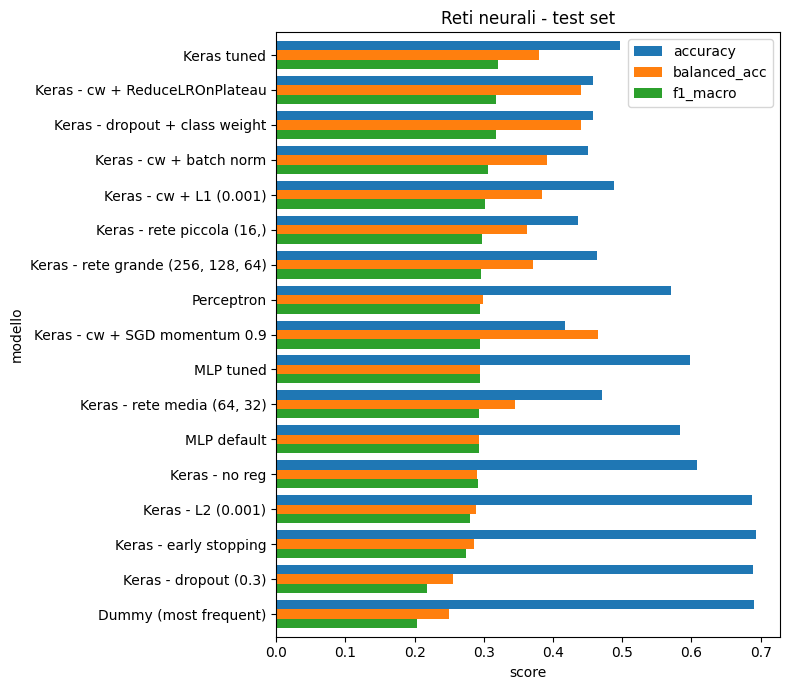

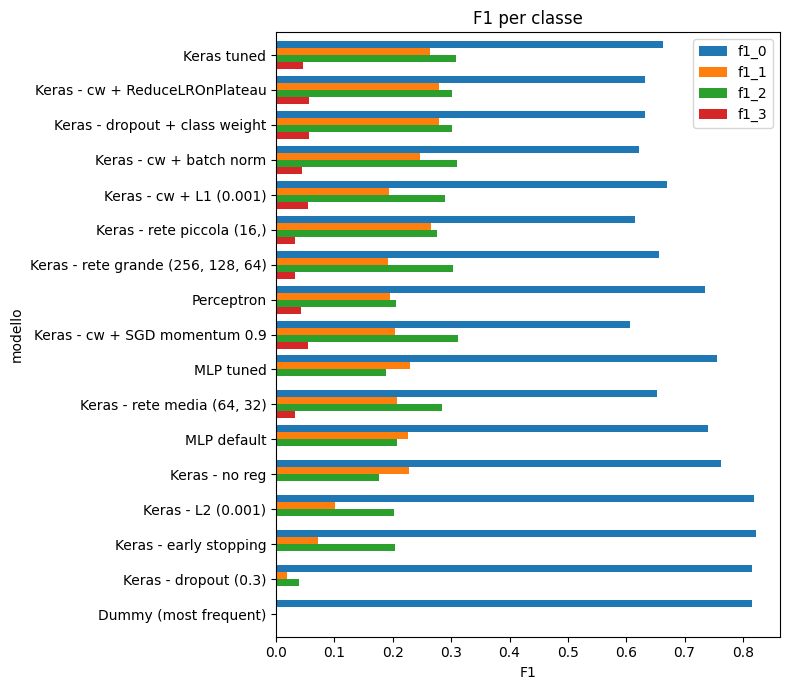

In [31]:
tab_finale[['accuracy', 'balanced_acc', 'f1_macro']].plot(kind='barh', figsize=(8, 7), width=.8)
plt.gca().invert_yaxis(); plt.xlabel('score'); plt.title('Reti neurali - test set')
plt.tight_layout(); plt.show()

f1_cols = [f'f1_{k}' for k in CLASSI]
tab_finale[f1_cols].plot(kind='barh', figsize=(8, 7), width=.8)
plt.gca().invert_yaxis(); plt.xlabel('F1'); plt.title('F1 per classe')
plt.tight_layout(); plt.show()

**Commento** (test set; qui compaiono per la prima volta i risultati sul test delle varianti delle sezioni 6 e 7).
- **Il miglior modello è la Keras tunata** (F1-macro 0.320, balanced accuracy 0.379, ROC AUC 0.674), scelta con la cross-validation. È anche il modello con la F1-macro più alta sul test.
- **Validation e test non concordano sull'ordine delle varianti.** Esempi: sul validation set L1 era la variante migliore (0.292 contro 0.276 del riferimento), sul test è peggiore (0.302 contro 0.317); la rete grande era la migliore delle tre architetture sul validation set, sul test le tre sono quasi alla pari (0.294–0.297). Con differenze di 0.01–0.02 e pochi esempi delle classi rare, **un singolo split non basta a distinguere le varianti**: per la scelta del modello finale ci si è quindi affidati alla cross-validation (sezione 8).
- Tutti i modelli con `class_weight` stanno fra 0.294 e 0.320 di F1-macro e hanno balanced accuracy fra 0.345 e 0.466; quelli **senza** pesi di classe hanno balanced accuracy fra 0.25 e 0.30 e quelli regolarizzati senza pesi scendono fino a 0.218 di F1-macro. **La gestione dello sbilanciamento conta più dell'architettura e delle tecniche di ottimizzazione.**
- **Accuracy e F1-macro vanno in direzioni opposte**: i modelli con accuracy più alta (~0.69) predicono quasi solo la classe 0, cioè sono quasi il Dummy; i migliori per F1-macro hanno accuracy ~0.45-0.50.
- **La classe 3 è la peggiore in tutti i modelli** (F1 ≤ 0.06): solo 70 esempi nel training e 18 nel test. Anche quando la rete la predice, la precision resta sotto il 3%.
- La classe 1 ("Mild") è difficile quasi quanto la 2 nonostante abbia più esempi: è una classe "di mezzo", con caratteristiche simili sia alla classe 0 sia alla 2.

📌 **Report:** questa tabella (anche ridotta a Dummy, Perceptron, MLP tuned, Keras no reg, Keras dropout + class weight, Keras tuned) e il grafico della F1 per classe; la frase sul disaccordo fra validation e test come motivazione per usare la CV. Va poi unita alle tabelle di LR e SVM (la LR finale ha F1-macro 0.311 sullo stesso test set, la SVM polinomiale 0.346, il modello finale del Gradient Boosting 0.328).

### Curve ROC e Precision-Recall dei due modelli tunati

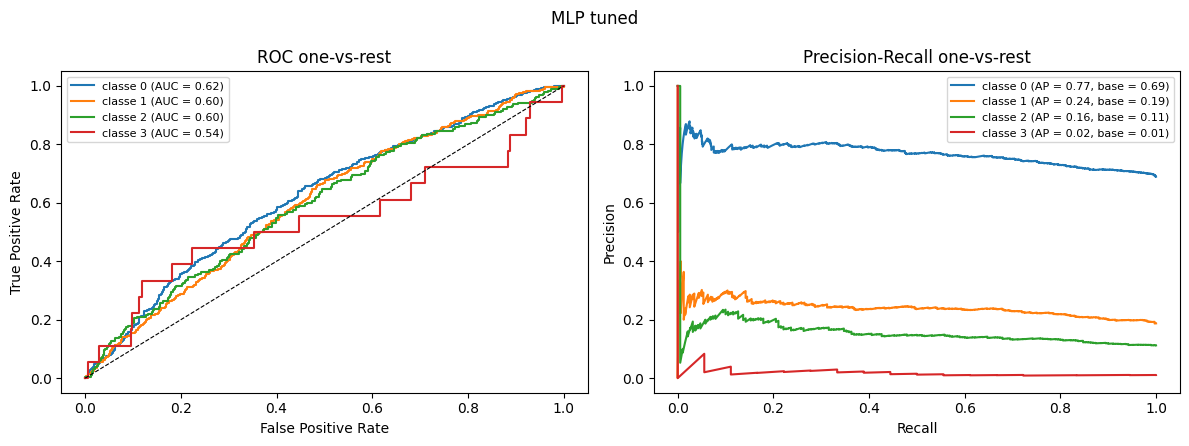

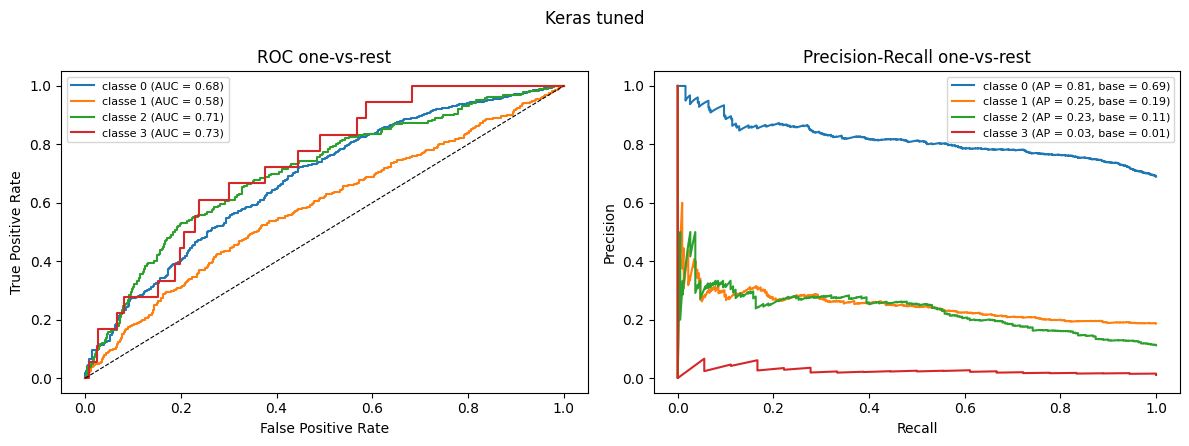

In [32]:
plot_roc_pr(mlp_best.predict_proba(X_test), 'MLP tuned')
plot_roc_pr(keras_best.predict_proba(X_test), 'Keras tuned')

**Commento.**
- **Keras tuned** ha ROC AUC per classe fra 0.58 (classe 1) e 0.73 (classe 3); l'**MLP** fra 0.54 e 0.62. La rete Keras ordina meglio i soggetti, soprattutto per le classi 2 e 3.
- La classe 1 ha l'AUC più bassa nella rete Keras: conferma che è la più difficile da separare dalle altre.
- Le curve **Precision-Recall** vanno lette rispetto alla base, cioè la frequenza della classe (riportata in legenda): per la classe 3 l'AP è 0.03 contro una base di 0.01, quindi meglio del caso ma con una precision bassissima a qualunque soglia. Per la classe 2 l'AP di Keras (0.23) è il doppio della base (0.11).
- L'AUC della classe 3 (0.73) va presa con cautela: è calcolata su 18 esempi positivi, e infatti la curva rossa procede a scalini.

📌 **Report:** le due figure ROC/PR (o solo quella di Keras tuned) + la frase sulla classe 3: AUC discreta ma precision bassissima, quindi il modello non è utilizzabile per individuare i casi gravi.

## 10. Sintesi per il report

**Riepilogo dei risultati da riportare.**

Varianti Keras confrontate sul **validation set** (sezioni 6-7):

| Variante | F1-macro val | Bal. acc. val | ROC AUC val | Minimo val_loss |
|---|---|---|---|---|
| no reg | 0.275 | 0.276 | 0.587 | epoca 3 |
| early stopping | 0.239 | 0.262 | 0.672 | epoca 3 |
| dropout 0.3 (senza pesi) | 0.211 | 0.252 | 0.686 | epoca 5 |
| dropout + class weight | 0.276 | 0.387 | 0.642 | epoca 5 |
| + L1 | 0.292 | 0.377 | 0.659 | epoca 28 |
| rete grande (256-128-64) | 0.297 | 0.377 | 0.671 | epoca 3 |

Modelli finali sul **test set**:

| Modello | F1-macro | Bal. acc. | ROC AUC | Accuracy |
|---|---|---|---|---|
| Dummy | 0.204 | 0.250 | 0.500 | 0.690 |
| Perceptron | 0.294 | 0.298 | – | 0.571 |
| MLP tuned (sklearn, F1-macro CV 0.299) | 0.294 | 0.294 | 0.589 | 0.598 |
| **Keras tuned (F1-macro CV 0.312)** | **0.320** | 0.379 | 0.674 | 0.496 |

**Messaggi chiave per il report**
1. **Overfitting rapidissimo**: senza regolarizzazione la validation loss è minima dopo 3 epoche e poi diverge; la training accuracy arriva al 100%.
2. **Criteri che evitano l'overfitting**: early stopping sulla validation loss con `restore_best_weights` (con la loss di validazione pesata come quella di training quando si usano i pesi di classe), L2 forte (1e-2), dropout 0.4, reti piccole. Nella rete finale la validation loss scende fino a circa l'epoca 18, contro l'epoca 3-5 delle reti meno regolarizzate.
3. **Evitare l'overfitting non basta**: early stopping, L2 e dropout senza pesi di classe fanno collassare la rete sulla classe 0 (accuracy alta, F1-macro bassa, recall della classe 1 fra lo 0,5% e il 5%). In sklearn lo stesso succede con `early_stopping=True`, che monitora l'accuracy.
4. **Il class weight è il parametro decisivo**: nel confronto controllato (6.4 → 6.5) la balanced accuracy sale da 0.252 a 0.387 e la F1-macro da 0.211 a 0.276; nel tuning, come indicazione, 0.289 contro 0.231 di F1-macro media in CV. L'MLP di sklearn non supporta i pesi di classe, ed è il motivo principale per cui la versione Keras va meglio.
5. **Anche con i pesi la rete va in overfitting presto** se misurata con la loss pesata (minimo all'epoca 5): i pesi amplificano gli errori sui pochi esempi rari, che la rete memorizza in fretta. Serve una regolarizzazione più forte (quella trovata dal tuning).
6. **Le tecniche di ottimizzazione aggiuntive danno differenze piccole**: Batch Normalization +0.007 e L1 +0.016 sul validation set, ma non confermate sul test; SGD con momentum peggiora (−0.029); ReduceLROnPlateau non ha effetto (l'early stopping ripristina i pesi prima della riduzione del learning rate).
7. **La capacità del modello determina quanto presto arriva l'overfitting** (rete grande: minimo all'epoca 3 e poi divergenza; rete piccola: leggero underfitting), ma con l'early stopping le tre architetture ottengono F1-macro simili.
8. **Validation e test non concordano sull'ordine delle varianti** (differenze di 0.01–0.02): un singolo split non basta a distinguerle, per questo il modello finale è scelto in cross-validation.
9. **Classe peggiore: la 3** in tutti i modelli (11 esempi nel validation set, 18 nel test, F1 ≤ 0.06); la classe 1 è difficile perché sta "in mezzo" fra 0 e 2.
10. **Accuracy fuorviante**: i modelli con l'accuracy più alta sono i peggiori per F1-macro.
11. **Le reti neurali non superano nettamente i modelli lineari** (Perceptron ≈ MLP; LR 0.311 contro Keras 0.320): il segnale nei dati è debole e in buona parte lineare. Nel Modulo 2 la F1-macro più alta in cross-validation è quella del Gradient Boosting (LightGBM: 0.341, contro 0.325 della SVM polinomiale e 0.312 della rete Keras); sul test la più alta resta quella della SVM (0.346), con il Gradient Boosting a 0.328 e la rete Keras a 0.320; le distanze fra i modelli restano dell'ordine della variabilità fra i fold.
12. **Variabilità fra esecuzioni**: le parti scikit-learn danno risultati identici su computer diversi, mentre le reti Keras possono variare fino a circa ±0.01 di F1-macro; differenze inferiori a questa soglia non vanno interpretate come miglioramenti reali.

**Grafici da inserire**: curve loss/accuracy della rete senza regolarizzazione (6.1), curve della rete con class weight (6.5), confronto delle validation loss (6.10), training/validation loss delle tre architetture (7), training del modello finale (8), confusion matrix e ROC/PR di Keras tuned, F1 per classe (sezione 9).

**Tabelle da inserire**: varianti sul validation set (6.10), architetture (7), configurazioni provate per MLP e Keras (prime righe), effetto di `early_stopping` (MLP) e di `class_weight` (Keras), tabella finale sul test.